# Actividad: Clasificación Multiclase y Regresión con Aprendizaje Automático y Redes Neuronales

**Objetivos de la actividad**
- Comparar el desempeño de clasificadores tradicionales (Random Forest, SVM, Regresión Logística) usando **GridSearchCV**.
- Aplicar **redes neuronales** (TensorFlow/Keras) a **clasificación multiclase**, probando estrategias de optimización e hiperparámetros.
- Aplicar **redes neuronales** a un problema de **regresión** y evaluar su rendimiento.

**Datasets:**
- *Clasificación (multiclase):* **Estimation of Obesity Levels Based On Eating Habits and Physical Condition** (UCI → réplica estable en DataHub). 7 clases de niveles de obesidad, 16+ features (numéricas y categóricas).
  - Enlace: https://archive.ics.uci.edu/dataset/544/estimation+of+obesity+levels+based+on+eating+habits+and+physical+condition
- *Regresión:* **Bike Sharing Demand** (UCI → réplica estable en DataHub). Estimación de demanda de bicicletas diarias.
  - Enlace: https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset

## 0. Configuración de entorno

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

import seaborn as sns
sns.set()
print("Versiones -> numpy", np.__version__, "| pandas", pd.__version__, "| sklearn OK | tf", tf.__version__)


Versiones -> numpy 2.0.2 | pandas 2.2.2 | sklearn OK | tf 2.19.0


## Dataset de Clasificación Multiclase: Estimation of Obesity Levels (carga por URL)

In [ ]:
!pip install ucimlrepo

In [ ]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
estimation_of_obesity_levels_based_on_eating_habits_and_physical_condition = fetch_ucirepo(id=544)

# data (as pandas dataframes)
X = estimation_of_obesity_levels_based_on_eating_habits_and_physical_condition.data.features
y = estimation_of_obesity_levels_based_on_eating_habits_and_physical_condition.data.targets

# metadata
print(estimation_of_obesity_levels_based_on_eating_habits_and_physical_condition.metadata)


{'uci_id': 544, 'name': 'Estimation of Obesity Levels Based On Eating Habits and Physical Condition ', 'repository_url': 'https://archive.ics.uci.edu/dataset/544/estimation+of+obesity+levels+based+on+eating+habits+and+physical+condition', 'data_url': 'https://archive.ics.uci.edu/static/public/544/data.csv', 'abstract': 'This dataset include data for the estimation of obesity levels in individuals from the countries of Mexico, Peru and Colombia, based on their eating habits and physical condition. ', 'area': 'Health and Medicine', 'tasks': ['Classification', 'Regression', 'Clustering'], 'characteristics': ['Multivariate'], 'num_instances': 2111, 'num_features': 16, 'feature_types': ['Integer'], 'demographics': ['Gender', 'Age'], 'target_col': ['NObeyesdad'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2019, 'last_updated': 'Tue Sep 10 2024', 'dataset_doi': '10.24432/C5H31Z', 'creators': [], 'intro_paper': {'ID': 358, 'type': 

- Verifica la tipología de las características

In [ ]:
X.info()
X.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Gender                          2111 non-null   object 
 1   Age                             2111 non-null   float64
 2   Height                          2111 non-null   float64
 3   Weight                          2111 non-null   float64
 4   family_history_with_overweight  2111 non-null   object 
 5   FAVC                            2111 non-null   object 
 6   FCVC                            2111 non-null   float64
 7   NCP                             2111 non-null   float64
 8   CAEC                            2111 non-null   object 
 9   SMOKE                           2111 non-null   object 
 10  CH2O                            2111 non-null   float64
 11  SCC                             2111 non-null   object 
 12  FAF                             21

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation


- Verifica cuantos registros existen por clase

In [ ]:
y.value_counts()

,count
NObeyesdad,
Obesity_Type_I,351
Obesity_Type_III,324
Obesity_Type_II,297
Overweight_Level_I,290
Overweight_Level_II,290
Normal_Weight,287
Insufficient_Weight,272


## **Ejercicio 1** — Clasificación Multiclase con clasificadores tradicionales + GridSearchCV

Modelos a comparar:
- **Random Forest**
- **Support Vector Machines (SVM)**
- **Logistic Regression**

**Metodología**
- Usar `StandardScaler` cuando corresponde (SVM y Regresión Logística).
- Tunning con `GridSearchCV` y validación cruzada estratificada (`StratifiedKFold`).
- Métricas: **accuracy**, **F1-macro** y matriz de confusión.


### Actividad - Ejercicio 1: Clasificación Multiclase con Clasificadores Tradicionales

Basado en el código proporcionado para el Ejercicio 1, realiza las siguientes tareas:

1.  **Revisión del código**: Familiarízate con el código que preprocesa y divide el dataset "Estimation of Obesity Levels". Entiende cómo se codifican las características categóricas y la variable objetivo.
2.  **GridSearchCV y Evaluación en Validación**: Ejecuta la celda que realiza `GridSearchCV` para cada uno de los clasificadores (Random Forest, SVM, Regresión Logística) utilizando los `param_grid` definidos y `StratifiedKFold` para la validación cruzada. Observa los mejores hiperparámetros encontrados y el mejor score (F1-macro) en validación para cada modelo.
3.  **Evaluación en el Conjunto de Prueba**: Ejecuta la celda que evalúa los mejores modelos obtenidos en el conjunto de prueba (`X_test`, `y_test`). Analiza el reporte de clasificación y la matriz de confusión para cada modelo.
4.  **Comparación y Análisis**: Responde a las siguientes preguntas basándote en los resultados obtenidos:
    *   ¿Qué modelo tradicional obtuvo el mejor rendimiento general en el conjunto de prueba (considerando Accuracy y F1-macro)?
    *   Comparando los resultados de validación y prueba, ¿hay indicios de sobreajuste en alguno de los modelos?
    *   ¿Qué clases parecen ser más difíciles de clasificar correctamente según las matrices de confusión? ¿Por qué crees que sucede esto?
    *   (Opcional) Modifica los `param_grid` para alguno de los modelos y vuelve a ejecutar el GridSearch. ¿Mejoraron los resultados? ¿Por qué crees que sí o no?


###**Preprocesamiento básico**

- Convierte las características categóricas en numéricas para realizar el procesamiento. (Recuerda que este paso es necesario dado que los algoritmos en su mayoría operan números).

In [ ]:
from sklearn.preprocessing import LabelEncoder

# Identificar columnas categóricas en el DataFrame completo X
categorical_features = X.select_dtypes(include=['object']).columns

# Aplicar LabelEncoder a cada columna categórica en el DataFrame completo X
X_encoded = X.copy() # Crear una copia para no modificar el DataFrame original si se necesita más adelante

for col in categorical_features:
    le = LabelEncoder()
    # Ajustar y transformar en el DataFrame completo
    X_encoded[col] = le.fit_transform(X_encoded[col])

# Ahora X_encoded contiene las características categóricas codificadas numéricamente.
# Asegurarnos de que todas las columnas sean numéricas para los modelos tradicionales
# Convertir a float para consistencia, aunque LabelEncoder produce ints
X_processed = X_encoded.astype(float)


print("Columnas categóricas codificadas:")
print(categorical_features)
print("\nPrimeras filas de los datos procesados:")
print(X_processed.head())
print("\nTipos de datos después del procesamiento:")
print(X_processed.dtypes)

# Ahora X_processed está listo para ser dividido
X = X_processed # Sobrescribir X con los datos procesados para usarlo en la división

Columnas categóricas codificadas:
Index(['Gender', 'family_history_with_overweight', 'FAVC', 'CAEC', 'SMOKE',
       'SCC', 'CALC', 'MTRANS'],
      dtype='object')

Primeras filas de los datos procesados:
   Gender   Age  Height  Weight  family_history_with_overweight  FAVC  FCVC  \
0     0.0  21.0    1.62    64.0                             1.0   0.0   2.0   
1     0.0  21.0    1.52    56.0                             1.0   0.0   3.0   
2     1.0  23.0    1.80    77.0                             1.0   0.0   2.0   
3     1.0  27.0    1.80    87.0                             0.0   0.0   3.0   
4     1.0  22.0    1.78    89.8                             0.0   0.0   2.0   

   NCP  CAEC  SMOKE  CH2O  SCC  FAF  TUE  CALC  MTRANS  
0  3.0   2.0    0.0   2.0  0.0  0.0  1.0   3.0     3.0  
1  3.0   2.0    1.0   3.0  1.0  3.0  0.0   2.0     3.0  
2  3.0   2.0    0.0   2.0  0.0  2.0  1.0   1.0     3.0  
3  3.0   2.0    0.0   2.0  0.0  2.0  0.0   1.0     4.0  
4  1.0   2.0    0.0   2.0  0.0  0.

- Codifica la salida en números también, debido a que inicialmente son tipo objeto. Esto es necesario para los algoritmos.

In [ ]:
from sklearn.preprocessing import LabelEncoder

# Aplicar LabelEncoder a la variable objetivo y
le_y = LabelEncoder()
y_encoded = le_y.fit_transform(y)

# Sobrescribir y con la versión codificada para usarla en la división
y = y_encoded

print("\nClases originales y sus códigos:")
# Crear un mapeo de la codificación para referencia
class_mapping = dict(zip(le_y.classes_, le_y.transform(le_y.classes_)))

# Convertir el mapeo de clases a un DataFrame para visualizarlo como tabla
class_mapping_df = pd.DataFrame(list(class_mapping.items()), columns=['Original Label', 'Encoded Label'])
print("Correspondencia entre etiquetas originales y codificadas:")
display(class_mapping_df)


Clases originales y sus códigos:
Correspondencia entre etiquetas originales y codificadas:


/usr/local/lib/python3.12/dist-packages/sklearn/preprocessing/_label.py:110: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


,Original Label,Encoded Label
0,Insufficient_Weight,0
1,Normal_Weight,1
2,Obesity_Type_I,2
3,Obesity_Type_II,3
4,Obesity_Type_III,4
5,Overweight_Level_I,5
6,Overweight_Level_II,6


- División en train/val/test (estratificada).

In [ ]:
# División estratificada
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42
)
X_valid, X_test, y_valid, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42
)

print('Tamaño del conjunto de Entrenamiento: ', X_train.shape)
print('Tamaño del conjunto de validación: ',X_valid.shape)
print('Tamaño del conjunto de prueba: ', X_test.shape)

Tamaño del conjunto de Entrenamiento:  (1477, 16)
Tamaño del conjunto de validación:  (317, 16)
Tamaño del conjunto de prueba:  (317, 16)


### **Entrenamiento y Gridsearch**
- Entrenar los algoritmos de clasificación con búsqueda de parametros por GridSearch

In [ ]:
# Para SVM y Regresión Logística, escalaremos los datos de entrenamiento y validación

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_valid_scaled = scaler.transform(X_valid)

# Grids razonables (pequeños para tiempos contenidos; puedes ampliarlos)
param_grid_rf = {
    'n_estimators': [150, 300],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5],
}

param_grid_svc = {
    'C': [0.5, 1, 2],
    'kernel': ['rbf'],
    'gamma': ['scale', 0.01, 0.001],
}

param_grid_lr = {
    'C': [0.5, 1, 2],
    'penalty': ['l2'],
    # solver 'lbfgs' por defecto para multinomial
}


cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

best_models = {}
model_results = []

# --- RandomForest ---
print("\n>>> GridSearch para RandomForest")
# RF no requiere escalado de features
rf = RandomForestClassifier(random_state=42, n_jobs=-1)
gs_rf = GridSearchCV(rf, param_grid_rf, cv=cv, scoring='f1_macro', n_jobs=-1, verbose=1)
gs_rf.fit(X_train, y_train)
print(f"Mejor score (cv F1-macro): {gs_rf.best_score_:.4f}")
print("Mejores params:", gs_rf.best_params_)
best_rf = gs_rf.best_estimator_
y_pred_rf = best_rf.predict(X_valid)
acc_rf = accuracy_score(y_valid, y_pred_rf)
f1m_rf = f1_score(y_valid, y_pred_rf, average='macro')
print(f"Validación -> Acc: {acc_rf:.4f} | F1-macro: {f1m_rf:.4f}")
best_models["RandomForest"] = best_rf
model_results.append({"Modelo": "RandomForest", "Accuracy_val": acc_rf, "F1_macro_val": f1m_rf})


# --- SVM ---
print("\n>>> GridSearch para SVM")
# SVM requiere escalado de features
svc = SVC(probability=True, random_state=42)
gs_svc = GridSearchCV(svc, param_grid_svc, cv=cv, scoring='f1_macro', n_jobs=-1, verbose=1)
gs_svc.fit(X_train_scaled, y_train) # Usamos datos escalados
print(f"Mejor score (cv F1-macro): {gs_svc.best_score_:.4f}")
print("Mejores params:", gs_svc.best_params_)
best_svc = gs_svc.best_estimator_
y_pred_svc = best_svc.predict(X_valid_scaled) # Usamos datos escalados para predicción
acc_svc = accuracy_score(y_valid, y_pred_svc)
f1m_svc = f1_score(y_valid, y_pred_svc, average='macro')
print(f"Validación -> Acc: {acc_svc:.4f} | F1-macro: {f1m_svc:.4f}")
best_models["SVM"] = best_svc
model_results.append({"Modelo": "SVM", "Accuracy_val": acc_svc, "F1_macro_val": f1m_svc})


# --- LogisticReg ---
print("\n>>> GridSearch para LogisticReg")
# LogisticReg requiere escalado de features
lr = LogisticRegression(max_iter=1000, multi_class='multinomial', n_jobs=-1, random_state=42)
gs_lr = GridSearchCV(lr, param_grid_lr, cv=cv, scoring='f1_macro', n_jobs=-1, verbose=1)
gs_lr.fit(X_train_scaled, y_train) # Usamos datos escalados
print(f"Mejor score (cv F1-macro): {gs_lr.best_score_:.4f}")
print("Mejores params:", gs_lr.best_params_)
best_lr = gs_lr.best_estimator_
y_pred_lr = best_lr.predict(X_valid_scaled) # Usamos datos escalados para predicción
acc_lr = accuracy_score(y_valid, y_pred_lr)
f1m_lr = f1_score(y_valid, y_pred_lr, average='macro')
print(f"Validación -> Acc: {acc_lr:.4f} | F1-macro: {f1m_lr:.4f}")
best_models["LogisticReg"] = best_lr
model_results.append({"Modelo": "LogisticReg", "Accuracy_val": acc_lr, "F1_macro_val": f1m_lr})


# Mostrar resultados en validación en forma de tabla
results_df_val = pd.DataFrame(model_results).sort_values("F1_macro_val", ascending=False)
print("\nResultados en conjunto de validación:")
display(results_df_val)


>>> GridSearch para RandomForest
Fitting 3 folds for each of 12 candidates, totalling 36 fits
Mejor score (cv F1-macro): 0.9493
Mejores params: {'max_depth': None, 'min_samples_split': 5, 'n_estimators': 300}
Validación -> Acc: 0.9401 | F1-macro: 0.9399

>>> GridSearch para SVM
Fitting 3 folds for each of 9 candidates, totalling 27 fits
Mejor score (cv F1-macro): 0.8825
Mejores params: {'C': 2, 'gamma': 'scale', 'kernel': 'rbf'}
Validación -> Acc: 0.8991 | F1-macro: 0.8994

>>> GridSearch para LogisticReg
Fitting 3 folds for each of 3 candidates, totalling 9 fits
Mejor score (cv F1-macro): 0.8848
Mejores params: {'C': 2, 'penalty': 'l2'}
Validación -> Acc: 0.8927 | F1-macro: 0.8897

Resultados en conjunto de validación:


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


,Modelo,Accuracy_val,F1_macro_val
0,RandomForest,0.940063,0.939867
1,SVM,0.899054,0.899400
2,LogisticReg,0.892744,0.889688


 ### **Evaluación de desempeño**
 - Evaluar el desempeño de los algoritmos en el conjunto de prueba


>>> Evaluación en conjunto de prueba: RandomForest
Reporte de clasificación - RandomForest:
                     precision    recall  f1-score   support

Insufficient_Weight       0.97      0.88      0.92        41
      Normal_Weight       0.75      0.91      0.82        43
     Obesity_Type_I       0.98      0.94      0.96        53
    Obesity_Type_II       1.00      1.00      1.00        45
   Obesity_Type_III       1.00      0.98      0.99        48
 Overweight_Level_I       0.86      0.86      0.86        43
Overweight_Level_II       0.98      0.93      0.95        44

           accuracy                           0.93       317
          macro avg       0.93      0.93      0.93       317
       weighted avg       0.94      0.93      0.93       317


>>> Evaluación en conjunto de prueba: SVM
Reporte de clasificación - SVM:
                     precision    recall  f1-score   support

Insufficient_Weight       0.88      0.93      0.90        41
      Normal_Weight       0.68     

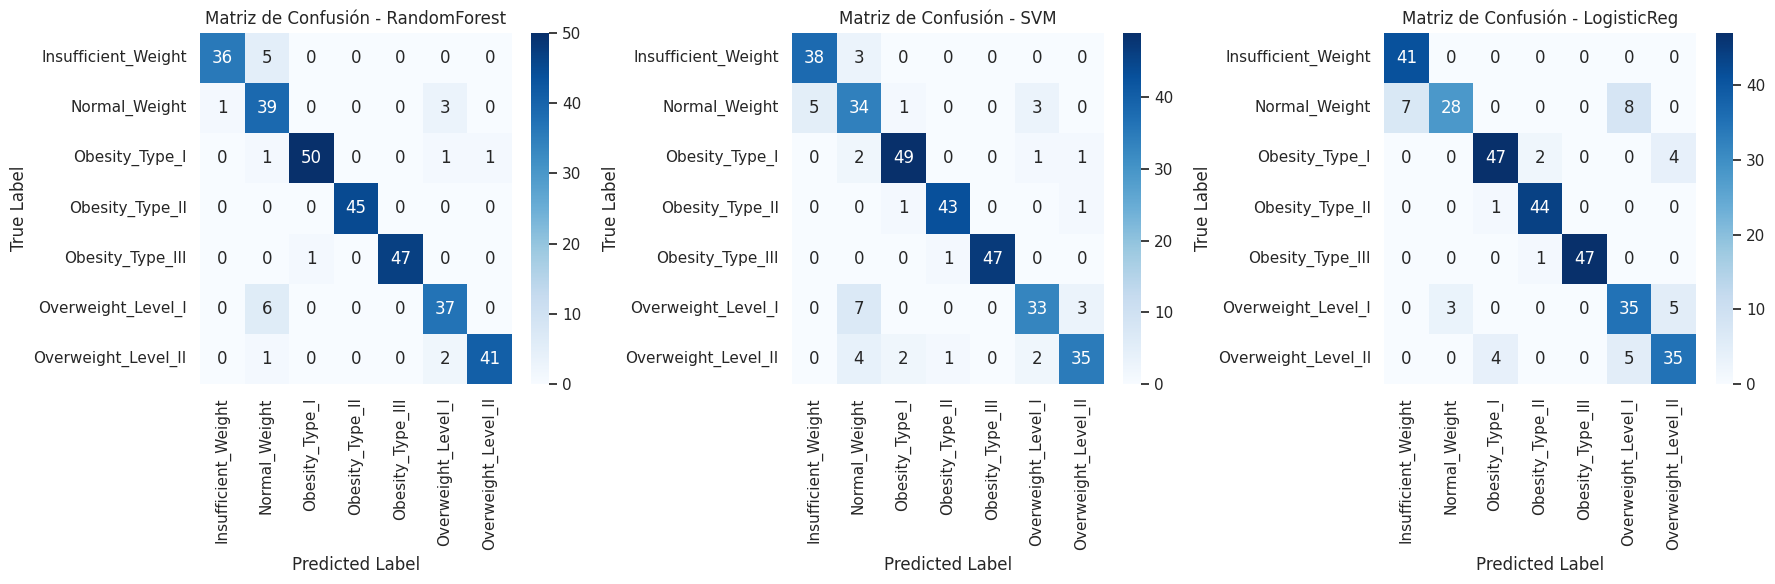

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Comparación en el conjunto de prueba y reportes individuales

# --- RandomForest ---
print("\n>>> Evaluación en conjunto de prueba: RandomForest")
y_pred_rf_test = best_models["RandomForest"].predict(X_test)
print("Reporte de clasificación - RandomForest:")
print(classification_report(y_test, y_pred_rf_test, target_names=le_y.classes_))


# --- SVM ---
print("\n>>> Evaluación en conjunto de prueba: SVM")
# Recordar escalar los datos de prueba para SVM
X_test_scaled = scaler.transform(X_test)
y_pred_svc_test = best_models["SVM"].predict(X_test_scaled)
print("Reporte de clasificación - SVM:")
print(classification_report(y_test, y_pred_svc_test, target_names=le_y.classes_))


# --- LogisticReg ---
print("\n>>> Evaluación en conjunto de prueba: LogisticReg")
# Recordar escalar los datos de prueba para LogisticReg
y_pred_lr_test = best_models["LogisticReg"].predict(X_test_scaled)
print("Reporte de clasificación - LogisticReg:")
print(classification_report(y_test, y_pred_lr_test, target_names=le_y.classes_))


# Visualización de Matrices de Confusión en un arreglo 1x3
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes = axes.flatten() # Para facilitar la indexación

# Matriz de Confusión - RandomForest
cm_rf = confusion_matrix(y_test, y_pred_rf_test)
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=le_y.classes_, yticklabels=le_y.classes_)
axes[0].set_title("Matriz de Confusión - RandomForest")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("True Label")

# Matriz de Confusión - SVM
cm_svc = confusion_matrix(y_test, y_pred_svc_test)
sns.heatmap(cm_svc, annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=le_y.classes_, yticklabels=le_y.classes_)
axes[1].set_title("Matriz de Confusión - SVM")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("True Label")

# Matriz de Confusión - LogisticReg
cm_lr = confusion_matrix(y_test, y_pred_lr_test)
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues', ax=axes[2],
            xticklabels=le_y.classes_, yticklabels=le_y.classes_)
axes[2].set_title("Matriz de Confusión - LogisticReg")
axes[2].set_xlabel("Predicted Label")
axes[2].set_ylabel("True Label")

plt.tight_layout()
plt.show()

### **Comparación y Análisis**:

Responde a las siguientes preguntas basándote en los resultados obtenidos:

- ¿Qué modelo tradicional obtuvo el mejor rendimiento general en el conjunto de prueba (considerando Accuracy y F1-macro)?
- Comparando los resultados de validación y prueba, ¿hay indicios de sobreajuste en alguno de los modelos?
- ¿Qué clases parecen ser más difíciles de clasificar correctamente según las matrices de confusión? ¿Por qué crees que sucede esto?
- (Opcional) Modifica los `param_grid` para alguno de los modelos y vuelve a ejecutar el GridSearch. ¿Mejoraron los resultados? ¿Por qué crees que sí o no?

## Respuesta
* El modelo tradicional que obtuvo el mejor rendimiento en el conjunto de test fue el **RandomForest**, tanto para el accuracy (F1-micro) como para el F1-macro.
* Analizando las métricas de entrenamiento, validación y pruebas (redondeadas a dos decimales), podríamos decir que no hay un sobre ajuste. Los valores para el entrenamiento, validación y prueba son muy cercanos entre sí, sugiriendo que los modelos son tan buenos para predecir nuevos datos como lo fueron en su fase de entrenamiento.

    * RandomForest
    |Conjunto|Accuracy|F1-macro|
    |-|-|-|
    |Entrenamiento|-|0.95|
    |Validacion|0.94|0.94|
    |Prueba|0.93|0.93|

    * SVM
    |Conjunto|Accuracy|F1-macro|
    |-|-|-|
    |Entrenamiento|-|0.88|
    |Validacion|0.90|0.90|
    |Prueba|0.88|0.88|  

    * LogisticReg
    |Conjunto|Accuracy|F1-macro|
    |-|-|-|
    |Entrenamiento|-|0.88|
    |Validacion|0.89|0.89|
    |Prueba|0.87|0.87|   

* Las clases para las cuales los modelos tuvieron más dificultad para clasificar son las que menos datos tenían en el dataset.

Parece que la dificultad para clasificar una clase está relacionada con la cantidad de datos para esa clase. Si vemos nuevamente el conteo de datos por categoría, podemos entender mejor los resultados de la matriz de confusión. Esto teniendo en cuenta la estrategia de división de los datos usada, donde se usó una estratificación basada en la etiqueta.

  |NObeyesdad|recuento	|
  |-|-|
  |Obesity_Type_I	|351|
  |Obesity_Type_III	|324|
  |Obesity_Type_II	|297|
  |Overweight_Level_I	|290|
  |Overweight_Level_II	|290|
  |Normal_Weight	|287|
  |Insufficient_Weight	|272|


## Ejercicio 2 — Clasificación Multiclase con Redes Neuronales (TensorFlow/Keras)

**Objetivo:** aplicar una MLP a Estimation of Obesity Levels y **variar hiperparámetros/estrategias** de optimización.
- Estandarizar features.
- Arquitectura base: `Dense -> Dropout -> Dense -> ... -> Softmax`.
- Estrategias a probar (ajusta libremente):
  - Optimizador: `SGD` vs `Adam`.
  - Tasa de aprendizaje fija vs **scheduler** (decay con `ExponentialDecay`).
  - `batch_size`: {32, 64}.
  - `dropout`: {0.0, 0.2, 0.4}.
- **EarlyStopping** para evitar sobreajuste.
- Métrica objetivo: **F1-macro** en validación (calculada externamente).


**En este ejercicio se toma como base la partición de la base datos realizada en el ejercicio anterior**

Es importante validar o recargar los datos para realizar el proceso correctamente

### Actividad - Ejercicio 2: Clasificación Multiclase con Redes Neuronales

Basado en el código proporcionado, realiza las siguientes tareas:

1.  **Revisión del código**: Familiarízate con la estructura de la red neuronal MLP, la función de compilación, el entrenamiento con `EarlyStopping` y la evaluación.
2.  **Experimentación con Hiperparámetros y Estrategias**:
    *   Modifica la celda de entrenamiento (`tUcT4OaHIZPr`) para probar diferentes combinaciones de los siguientes elementos:
        *   **Optimizador**: Cambia de `Adam` a `SGD`. Si usas SGD, experimenta con su tasa de aprendizaje (`learning_rate`).
        *   **Tasa de Aprendizaje (LR)**: Prueba una tasa de aprendizaje fija diferente para el optimizador `Adam` (ej. 1e-4, 1e-2).
        *   **Scheduler de Tasa de Aprendizaje**: Implementa un `ExponentialDecay` u otro scheduler para ver si ayuda a la convergencia. Compara con una LR fija.
        *   **Tamaño del Batch (`batch_size`)**: Cambia entre 32 y 64.
        *   **Dropout**: Introduce capas `Dropout` con diferentes tasas (ej. 0.1, 0.2, 0.4) después de las capas densas para ver su efecto en el sobreajuste.
        *   **Arquitectura de la Red**: (Opcional) Añade o quita capas densas, o cambia el número de neuronas en las capas existentes.
    *   Entrena el modelo con cada combinación y observa las métricas de validación (especialmente la pérdida de validación y accuracy/F1-macro si la calculas) y las curvas de entrenamiento.
3.  **Análisis de Resultados**:
    *   Compara el rendimiento de las diferentes configuraciones probadas en el conjunto de validación. ¿Qué combinación de hiperparámetros y estrategias funcionó mejor?
    *   Analiza las curvas de entrenamiento (pérdida y métricas) para cada experimento. ¿Observas sobreajuste en alguna configuración? ¿Ayudó `EarlyStopping` a mitigarlo?
    *   ¿Cómo se compara el rendimiento del mejor modelo de red neuronal con el mejor clasificador tradicional del Ejercicio 1 en el conjunto de prueba?
    *   Considerando las matrices de confusión, ¿la red neuronal tiene problemas similares con ciertas clases que los modelos tradicionales?

### **Estandarización de los datos**

In [ ]:
from tensorflow.keras.utils import to_categorical
from sklearn.preprocessing import StandardScaler
import numpy as np # Asegurarse de que numpy esté importado

# Estandarización
scaler_cls = StandardScaler()
X_train_s = scaler_cls.fit_transform(X_train)
X_valid_s = scaler_cls.transform(X_valid)
X_test_s  = scaler_cls.transform(X_test)

# Obtener el número de clases únicas desde y_train (que es un numpy array)
num_classes = len(np.unique(y_train))
# Necesitamos class_names para visualizar matrices de confusión más adelante.

# Convertir etiquetas a formato one-hot encoding
y_train_cat = to_categorical(y_train, num_classes=num_classes)
y_valid_cat = to_categorical(y_valid, num_classes=num_classes) # También one-hot encode validation set
y_test_cat = to_categorical(y_test, num_classes=num_classes)


print("Datos listos para el entrenamiento de la red neuronal.\n")
print(f"X_train_s shape: {X_train_s.shape}")
print(f"y_train_cat shape: {y_train_cat.shape}")
print(f"X_valid_s shape: {X_valid_s.shape}")
print(f"y_valid_cat shape: {y_valid_cat.shape}")
print(f"X_test_s shape: {X_test_s.shape}")
print(f"y_test_cat shape: {y_test_cat.shape}")
print(f"Número de clases: {num_classes}")

Datos listos para el entrenamiento de la red neuronal.

X_train_s shape: (1477, 16)
y_train_cat shape: (1477, 7)
X_valid_s shape: (317, 16)
y_valid_cat shape: (317, 7)
X_test_s shape: (317, 16)
y_test_cat shape: (317, 7)
Número de clases: 7


### **Compilar y Entrenar el modelo**

Model: "sequential_61"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_243 (Dense)               │ (None, 64)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_244 (Dense)               │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_245 (Dense)               │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_246 (Dense)               │ (None, 7)              │           119 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,815 (14.90 KB)

 Trainable params: 3,815 (14.90 KB)

 Non-trainable params: 0 (0.00 B)

Modelo construido y compilado.

--- Entrenamiento del Modelo ---
Epoch 1/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.2663 - loss: 1.8910 - val_accuracy: 0.3885 - val_loss: 1.7162
Epoch 2/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4233 - loss: 1.6143 - val_accuracy: 0.4966 - val_loss: 1.4822
Epoch 3/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5587 - loss: 1.3605 - val_accuracy: 0.5541 - val_loss: 1.2844
Epoch 4/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6396 - loss: 1.1529 - val_accuracy: 0.6115 - val_loss: 1.1090
Epoch 5/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6703 - loss: 0.9692 - val_accuracy: 0.6419 - val_loss: 0.9530
Epoch 6/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7192 - loss: 0.8025 - val_accuracy: 0.6959 - val_loss: 0.8457
Epoch 7/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8006 - loss: 0.6732 - val_accuracy: 0.7466 - val_loss: 0.7381
Epoch 8/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - 

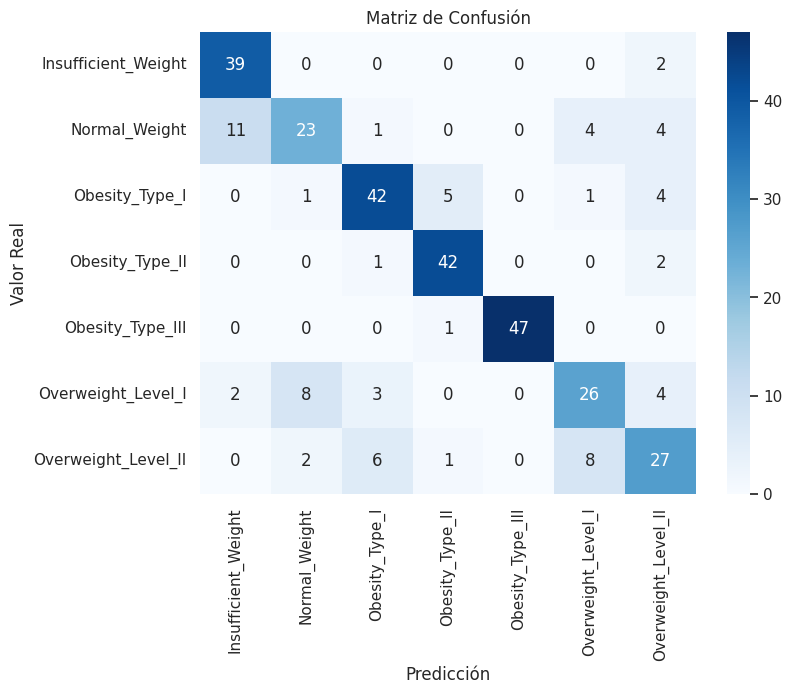

In [ ]:
# -----------------------------------------------------------------------------
# CONSTRUCCIÓN Y COMPILACIÓN DEL MODELO
# -----------------------------------------------------------------------------
# Definir la arquitectura de la red neuronal de forma secuencial

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.optimizers import Adam, SGD
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers.schedules import ExponentialDecay

model = Sequential([
    # Capa de entrada con una forma igual al número de características
    Input(shape=(X_train_scaled.shape[1],)),
    # Primera capa oculta con 64 neuronas y función de activación ReLU
    Dense(64, activation='relu'),
    # Segunda capa oculta con 32 neuronas
    Dense(32, activation='relu'),
    Dense(16, activation='relu'),
    # Capa de salida con una neurona por cada clase y activación Softmax para clasificación
    Dense(num_classes, activation='softmax')
])

# Compilar el modelo, configurando cómo aprenderá
model.compile(
    optimizer='adam',                   # Optimizador que ajusta los pesos del modelo
    loss='categorical_crossentropy',    # Función de pérdida para clasificación multiclase
    metrics=['accuracy']                # Métrica a monitorear durante el entrenamiento
)

# Mostrar un resumen de la arquitectura del modelo
model.summary()
print("Modelo construido y compilado.\n")

# -----------------------------------------------------------------------------
# ENTRENAMIENTO DEL MODELO
# -----------------------------------------------------------------------------
print("--- Entrenamiento del Modelo ---")
# Configurar EarlyStopping para detener el entrenamiento si no hay mejora
early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

# Entrenar el modelo con los datos de entrenamiento
history_0 = model.fit(
    X_train_scaled,
    y_train_cat,
    epochs=10,                     # Número máximo de pasadas por los datos
    batch_size=32,                  # Número de muestras por actualización de gradiente
    validation_split=0.2,           # Porcentaje de datos de entrenamiento para validación
    callbacks=[early_stopping],     # Aplicar el callback de EarlyStopping
    verbose=1                       # Mostrar el progreso del entrenamiento
)

print("Entrenamiento finalizado.\n")

# -----------------------------------------------------------------------------
# EVALUACIÓN DEL MODELO
# -----------------------------------------------------------------------------
print("--- Evaluación del Modelo ---")
# El modelo predice probabilidades para cada clase
y_pred_prob = model.predict(X_test_scaled)

# Convertir las probabilidades a la clase predicha (la de mayor probabilidad)
y_pred = np.argmax(y_pred_prob, axis=1) #[0,0,1] ---> 2

# Generar el reporte de clasificación con las métricas principales
print("Reporte de Clasificación:")
reporte_0 = classification_report(y_test, y_pred)
print(reporte_0)

# Calcular la precisión (accuracy) global
accuracy = accuracy_score(y_test, y_pred)
print(f"Precisión (Accuracy) General: {accuracy:.4f}\n")

# Generar y mostrar la matriz de confusión para visualizar el rendimiento
print("Matriz de Confusión:")
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
# Usar le_y.classes_ para las etiquetas de los ejes de la matriz de confusión
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=le_y.classes_, yticklabels=le_y.classes_)
plt.xlabel('Predicción')
plt.ylabel('Valor Real')
plt.title('Matriz de Confusión')
plt.show()

- Al graficar el Accuracy y el Loss de entrenamiento y validación se observa el siguiente resultado:

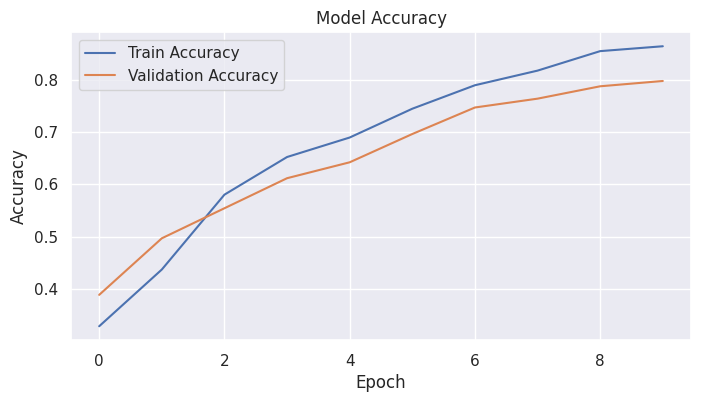

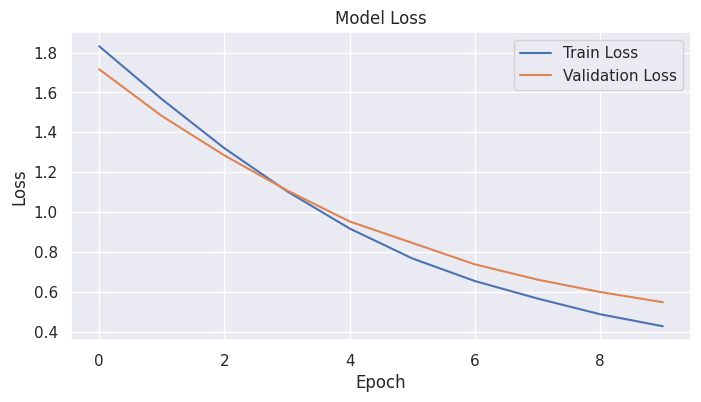

In [ ]:
import matplotlib.pyplot as plt

# Graficar Accuracy de entrenamiento y validación
plt.figure(figsize=(8, 4))
plt.plot(history_0.history['accuracy'], label='Train Accuracy')
plt.plot(history_0.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

# Graficar Loss de entrenamiento y validación
plt.figure(figsize=(8, 4))
plt.plot(history_0.history['loss'], label='Train Loss')
plt.plot(history_0.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

Model: "sequential_62"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_247 (Dense)               │ (None, 64)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_248 (Dense)               │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_249 (Dense)               │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_250 (Dense)               │ (None, 7)              │           119 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,815 (14.90 KB)

 Trainable params: 3,815 (14.90 KB)

 Non-trainable params: 0 (0.00 B)

Modelo construido y compilado.

--- Entrenamiento del Modelo ---
Epoch 1/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.1713 - loss: 2.0986 - val_accuracy: 0.1588 - val_loss: 2.0085
Epoch 2/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1601 - loss: 2.0497 - val_accuracy: 0.1858 - val_loss: 1.9685
Epoch 3/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.1859 - loss: 1.9960 - val_accuracy: 0.2027 - val_loss: 1.9376
Epoch 4/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.2075 - loss: 1.9478 - val_accuracy: 0.2196 - val_loss: 1.9123
Epoch 5/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.2521 - loss: 1.9257 - val_accuracy: 0.2466 - val_loss: 1.8886
Epoch 6/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.2661 - loss: 1.8849 - val_accuracy: 0.2939 - val_loss: 1.8673
Epoch 7/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.3119 - loss: 1.8626 - val_accuracy: 0.3682 - val_loss: 1.8455
Epoch 8/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - 

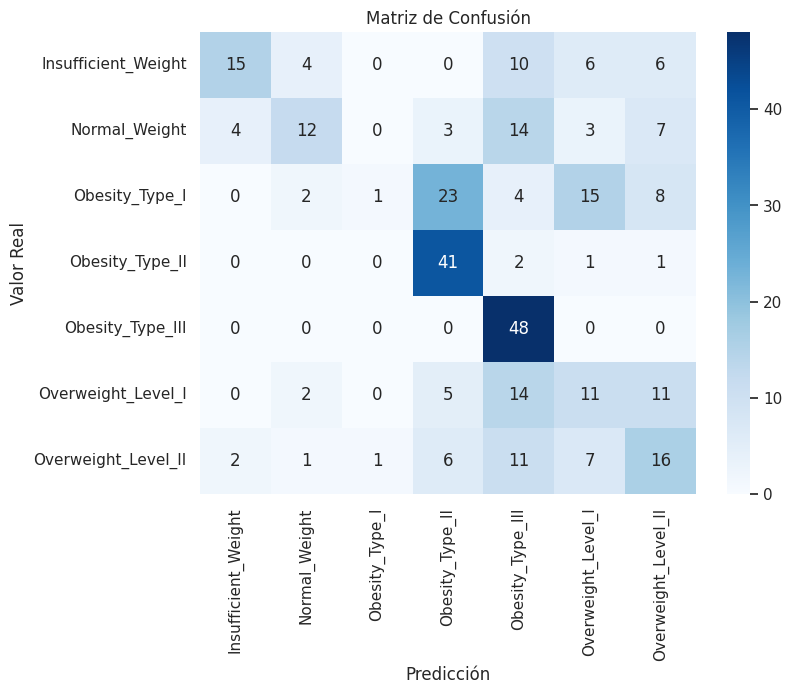

In [ ]:
# @title
# -----------------------------------------------------------------------------
# CONSTRUCCIÓN Y COMPILACIÓN DEL MODELO
# -----------------------------------------------------------------------------
# Definir la arquitectura de la red neuronal de forma secuencial

model = Sequential([
    # Capa de entrada con una forma igual al número de características
    Input(shape=(X_train_scaled.shape[1],)),
    # Primera capa oculta con 64 neuronas y función de activación ReLU
    Dense(64, activation='relu'),
    # Segunda capa oculta con 32 neuronas
    Dense(32, activation='relu'),
    Dense(16, activation='relu'),
    # Capa de salida con una neurona por cada clase y activación Softmax para clasificación
    Dense(num_classes, activation='softmax')
])


# Modificamos el learning rate para el optimizador adam

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4), # Añadido learning_rate
    loss='categorical_crossentropy',    # Función de pérdida para clasificación multiclase
    metrics=['accuracy']                # Métrica a monitorear durante el entrenamiento
)

# Mostrar un resumen de la arquitectura del modelo
model.summary()
print("Modelo construido y compilado.\n")

# -----------------------------------------------------------------------------
# ENTRENAMIENTO DEL MODELO
# -----------------------------------------------------------------------------
print("--- Entrenamiento del Modelo ---")
# Configurar EarlyStopping para detener el entrenamiento si no hay mejora
early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

# Entrenar el modelo con los datos de entrenamiento
history_1 = model.fit(
    X_train_scaled,
    y_train_cat,
    epochs=10,                     # Número máximo de pasadas por los datos
    batch_size=32,                  # Número de muestras por actualización de gradiente
    validation_split=0.2,           # Porcentaje de datos de entrenamiento para validación
    callbacks=[early_stopping],     # Aplicar el callback de EarlyStopping
    verbose=1                       # Mostrar el progreso del entrenamiento
)

print("Entrenamiento finalizado.\n")

# -----------------------------------------------------------------------------
# EVALUACIÓN DEL MODELO
# -----------------------------------------------------------------------------
print("--- Evaluación del Modelo ---")
# El modelo predice probabilidades para cada clase
y_pred_prob = model.predict(X_test_scaled)

# Convertir las probabilidades a la clase predicha (la de mayor probabilidad)
y_pred = np.argmax(y_pred_prob, axis=1) #[0,0,1] ---> 2

# Generar el reporte de clasificación con las métricas principales
print("Reporte de Clasificación:")
reporte_1 = classification_report(y_test, y_pred)
print(reporte_1)

# Calcular la precisión (accuracy) global
accuracy = accuracy_score(y_test, y_pred)
print(f"Precisión (Accuracy) General: {accuracy:.4f}\n")

# Generar y mostrar la matriz de confusión para visualizar el rendimiento
print("Matriz de Confusión:")
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
# Usar le_y.classes_ para las etiquetas de los ejes de la matriz de confusión
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=le_y.classes_, yticklabels=le_y.classes_)
plt.xlabel('Predicción')
plt.ylabel('Valor Real')
plt.title('Matriz de Confusión')
plt.show()

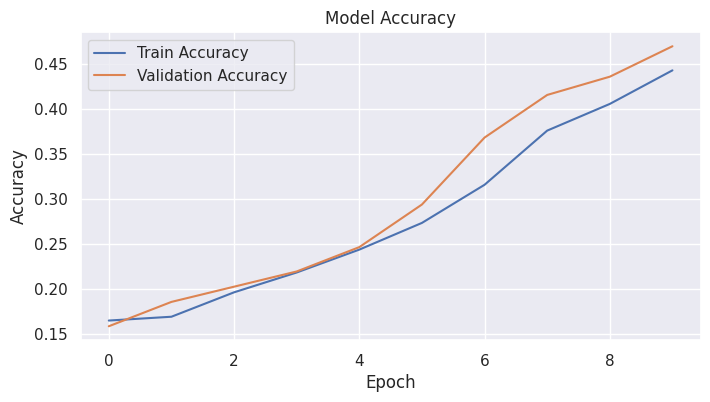

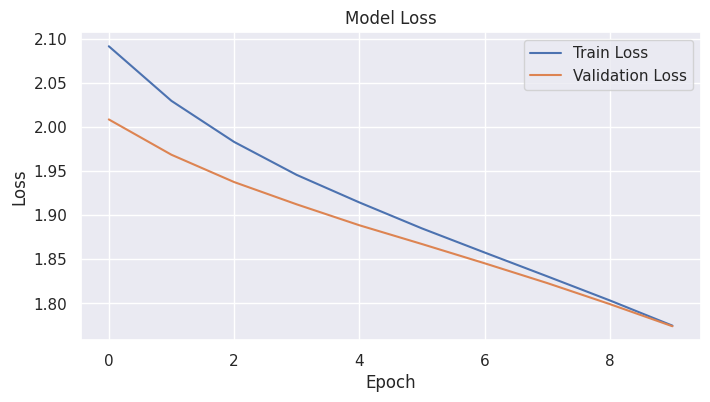

In [ ]:
# @title
# Graficar Accuracy de entrenamiento y validación
plt.figure(figsize=(8, 4))
plt.plot(history_1.history['accuracy'], label='Train Accuracy')
plt.plot(history_1.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

# Graficar Loss de entrenamiento y validación
plt.figure(figsize=(8, 4))
plt.plot(history_1.history['loss'], label='Train Loss')
plt.plot(history_1.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

Model: "sequential_63"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_251 (Dense)               │ (None, 64)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_252 (Dense)               │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_253 (Dense)               │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_254 (Dense)               │ (None, 7)              │           119 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,815 (14.90 KB)

 Trainable params: 3,815 (14.90 KB)

 Non-trainable params: 0 (0.00 B)

Modelo construido y compilado.

--- Entrenamiento del Modelo ---
Epoch 1/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.3700 - loss: 1.6022 - val_accuracy: 0.6554 - val_loss: 0.8033
Epoch 2/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7347 - loss: 0.6402 - val_accuracy: 0.8209 - val_loss: 0.4398
Epoch 3/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8960 - loss: 0.3062 - val_accuracy: 0.8581 - val_loss: 0.3699
Epoch 4/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9403 - loss: 0.2013 - val_accuracy: 0.9155 - val_loss: 0.2827
Epoch 5/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9474 - loss: 0.1448 - val_accuracy: 0.8986 - val_loss: 0.2742
Epoch 6/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9597 - loss: 0.1259 - val_accuracy: 0.9020 - val_loss: 0.2795
Epoch 7/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9471 - loss: 0.1320 - val_accuracy: 0.9155 - val_loss: 0.2845
Epoch 8/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - 

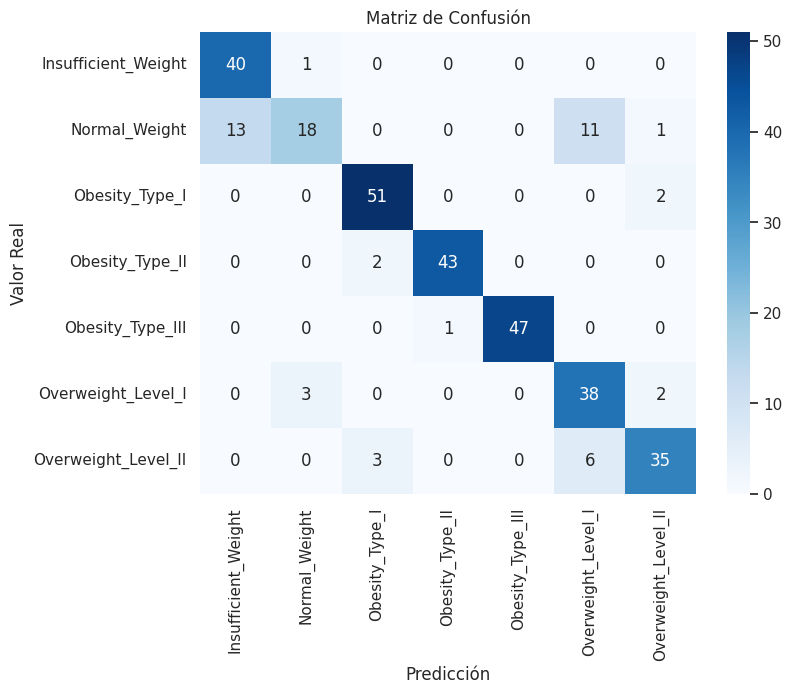

In [ ]:
# @title
# -----------------------------------------------------------------------------
# CONSTRUCCIÓN Y COMPILACIÓN DEL MODELO
# -----------------------------------------------------------------------------
# Definir la arquitectura de la red neuronal de forma secuencial

model = Sequential([
    # Capa de entrada con una forma igual al número de características
    Input(shape=(X_train_scaled.shape[1],)),
    # Primera capa oculta con 64 neuronas y función de activación ReLU
    Dense(64, activation='relu'),
    # Segunda capa oculta con 32 neuronas
    Dense(32, activation='relu'),
    Dense(16, activation='relu'),
    # Capa de salida con una neurona por cada clase y activación Softmax para clasificación
    Dense(num_classes, activation='softmax')
])


# Modificamos el learning rate para el optimizador adam mucho más rápido

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-2), # Añadido learning_rate
    loss='categorical_crossentropy',    # Función de pérdida para clasificación multiclase
    metrics=['accuracy']                # Métrica a monitorear durante el entrenamiento
)

# Mostrar un resumen de la arquitectura del modelo
model.summary()
print("Modelo construido y compilado.\n")

# -----------------------------------------------------------------------------
# ENTRENAMIENTO DEL MODELO
# -----------------------------------------------------------------------------
print("--- Entrenamiento del Modelo ---")
# Configurar EarlyStopping para detener el entrenamiento si no hay mejora
early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

# Entrenar el modelo con los datos de entrenamiento
history_1 = model.fit(
    X_train_scaled,
    y_train_cat,
    epochs=10,                     # Número máximo de pasadas por los datos
    batch_size=32,                  # Número de muestras por actualización de gradiente
    validation_split=0.2,           # Porcentaje de datos de entrenamiento para validación
    callbacks=[early_stopping],     # Aplicar el callback de EarlyStopping
    verbose=1                       # Mostrar el progreso del entrenamiento
)

print("Entrenamiento finalizado.\n")

# -----------------------------------------------------------------------------
# EVALUACIÓN DEL MODELO
# -----------------------------------------------------------------------------
print("--- Evaluación del Modelo ---")
# El modelo predice probabilidades para cada clase
y_pred_prob = model.predict(X_test_scaled)

# Convertir las probabilidades a la clase predicha (la de mayor probabilidad)
y_pred = np.argmax(y_pred_prob, axis=1) #[0,0,1] ---> 2

# Generar el reporte de clasificación con las métricas principales
print("Reporte de Clasificación:")
reporte_2 = classification_report(y_test, y_pred)
print(reporte_2)

# Calcular la precisión (accuracy) global
accuracy = accuracy_score(y_test, y_pred)
print(f"Precisión (Accuracy) General: {accuracy:.4f}\n")

# Generar y mostrar la matriz de confusión para visualizar el rendimiento
print("Matriz de Confusión:")
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
# Usar le_y.classes_ para las etiquetas de los ejes de la matriz de confusión
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=le_y.classes_, yticklabels=le_y.classes_)
plt.xlabel('Predicción')
plt.ylabel('Valor Real')
plt.title('Matriz de Confusión')
plt.show()

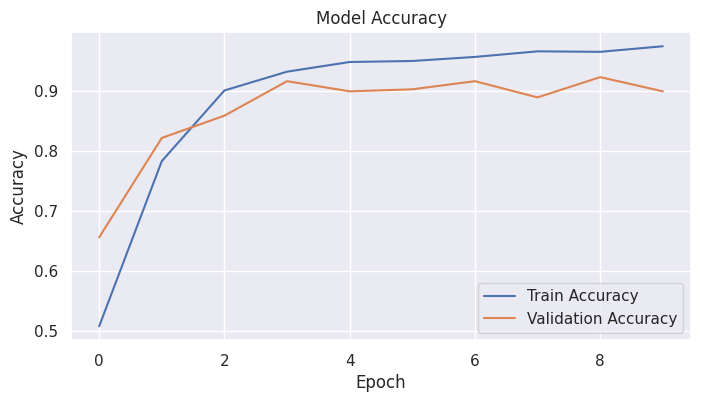

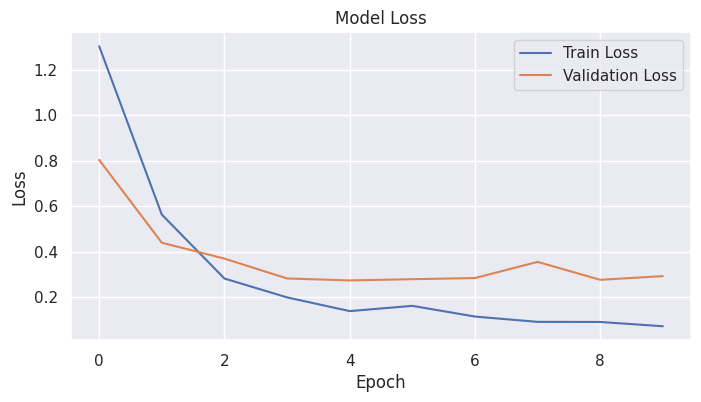

In [ ]:
# @title
# Graficar Accuracy de entrenamiento y validación
plt.figure(figsize=(8, 4))
plt.plot(history_1.history['accuracy'], label='Train Accuracy')
plt.plot(history_1.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

# Graficar Loss de entrenamiento y validación
plt.figure(figsize=(8, 4))
plt.plot(history_1.history['loss'], label='Train Loss')
plt.plot(history_1.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

Model: "sequential_64"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_255 (Dense)               │ (None, 64)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_256 (Dense)               │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_257 (Dense)               │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_258 (Dense)               │ (None, 7)              │           119 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,815 (14.90 KB)

 Trainable params: 3,815 (14.90 KB)

 Non-trainable params: 0 (0.00 B)

Modelo construido y compilado.

--- Entrenamiento del Modelo ---
Epoch 1/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.1172 - loss: 1.9997 - val_accuracy: 0.0878 - val_loss: 2.0235
Epoch 2/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1238 - loss: 1.9829 - val_accuracy: 0.0946 - val_loss: 2.0072
Epoch 3/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1270 - loss: 1.9853 - val_accuracy: 0.0946 - val_loss: 1.9917
Epoch 4/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1319 - loss: 1.9685 - val_accuracy: 0.1047 - val_loss: 1.9773
Epoch 5/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1465 - loss: 1.9525 - val_accuracy: 0.1216 - val_loss: 1.9638
Epoch 6/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1560 - loss: 1.9386 - val_accuracy: 0.1318 - val_loss: 1.9512
Epoch 7/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.1757 - loss: 1.9123 - val_accuracy: 0.1351 - val_loss: 1.9392
Epoch 8/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - 

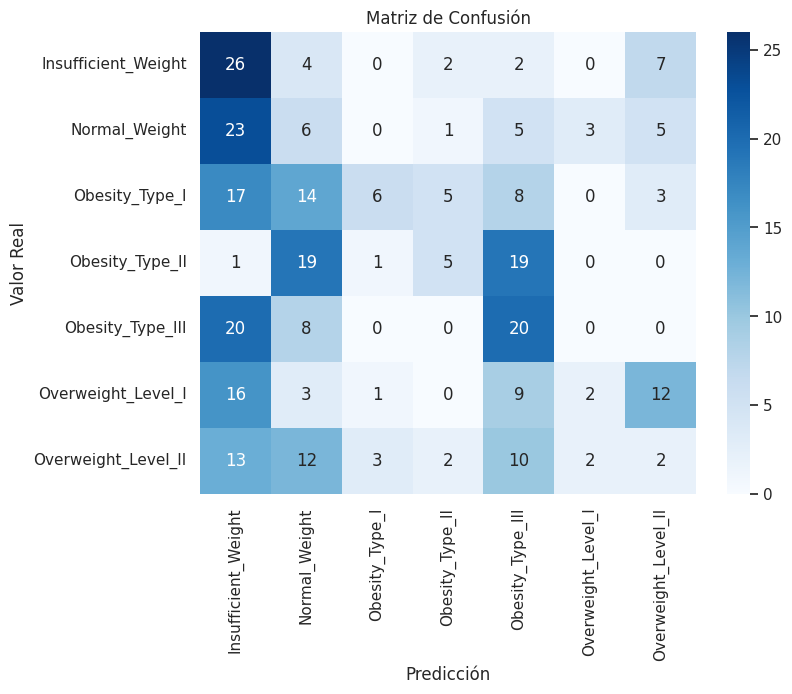

In [ ]:
# @title
# -----------------------------------------------------------------------------
# CONSTRUCCIÓN Y COMPILACIÓN DEL MODELO
# -----------------------------------------------------------------------------
# Definir la arquitectura de la red neuronal de forma secuencial

model = Sequential([
    # Capa de entrada con una forma igual al número de características
    Input(shape=(X_train_scaled.shape[1],)),
    # Primera capa oculta con 64 neuronas y función de activación ReLU
    Dense(64, activation='relu'),
    # Segunda capa oculta con 32 neuronas
    Dense(32, activation='relu'),
    Dense(16, activation='relu'),
    # Capa de salida con una neurona por cada clase y activación Softmax para clasificación
    Dense(num_classes, activation='softmax')
])


# Modificamos el learning rate para el optimizador SGD

model.compile(
    optimizer=tf.keras.optimizers.SGD(learning_rate=1e-3), # Añadido learning_rate
    loss='categorical_crossentropy',    # Función de pérdida para clasificación multiclase
    metrics=['accuracy']                # Métrica a monitorear durante el entrenamiento
)

# Mostrar un resumen de la arquitectura del modelo
model.summary()
print("Modelo construido y compilado.\n")

# -----------------------------------------------------------------------------
# ENTRENAMIENTO DEL MODELO
# -----------------------------------------------------------------------------
print("--- Entrenamiento del Modelo ---")
# Configurar EarlyStopping para detener el entrenamiento si no hay mejora
early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

# Entrenar el modelo con los datos de entrenamiento
history_2 = model.fit(
    X_train_scaled,
    y_train_cat,
    epochs=10,                     # Número máximo de pasadas por los datos
    batch_size=32,                  # Número de muestras por actualización de gradiente
    validation_split=0.2,           # Porcentaje de datos de entrenamiento para validación
    callbacks=[early_stopping],     # Aplicar el callback de EarlyStopping
    verbose=1                       # Mostrar el progreso del entrenamiento
)

print("Entrenamiento finalizado.\n")

# -----------------------------------------------------------------------------
# EVALUACIÓN DEL MODELO
# -----------------------------------------------------------------------------
print("--- Evaluación del Modelo ---")
# El modelo predice probabilidades para cada clase
y_pred_prob = model.predict(X_test_scaled)

# Convertir las probabilidades a la clase predicha (la de mayor probabilidad)
y_pred = np.argmax(y_pred_prob, axis=1) #[0,0,1] ---> 2

# Generar el reporte de clasificación con las métricas principales
print("Reporte de Clasificación:")
reporte_2 = classification_report(y_test, y_pred)
print(reporte_2)

# Calcular la precisión (accuracy) global
accuracy = accuracy_score(y_test, y_pred)
print(f"Precisión (Accuracy) General: {accuracy:.4f}\n")

# Generar y mostrar la matriz de confusión para visualizar el rendimiento
print("Matriz de Confusión:")
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
# Usar le_y.classes_ para las etiquetas de los ejes de la matriz de confusión
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=le_y.classes_, yticklabels=le_y.classes_)
plt.xlabel('Predicción')
plt.ylabel('Valor Real')
plt.title('Matriz de Confusión')
plt.show()

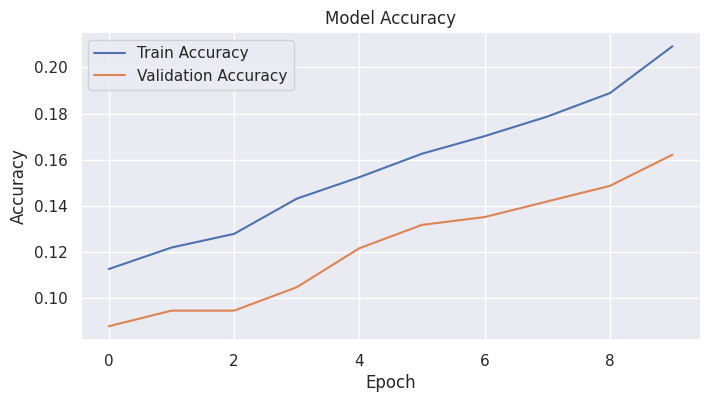

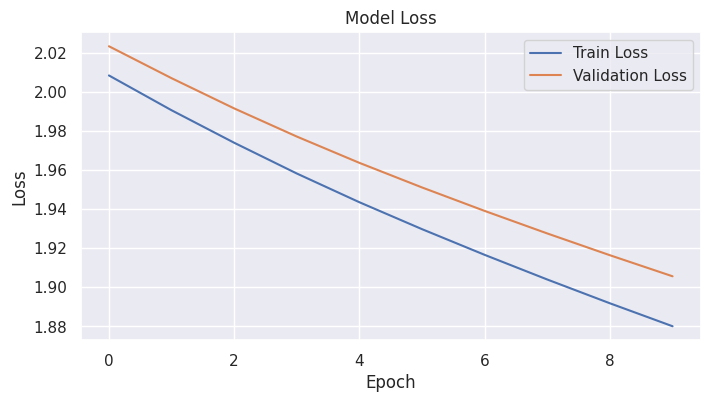

In [ ]:
# @title
# Graficar Accuracy de entrenamiento y validación
plt.figure(figsize=(8, 4))
plt.plot(history_2.history['accuracy'], label='Train Accuracy')
plt.plot(history_2.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

# Graficar Loss de entrenamiento y validación
plt.figure(figsize=(8, 4))
plt.plot(history_2.history['loss'], label='Train Loss')
plt.plot(history_2.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

Model: "sequential_65"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_259 (Dense)               │ (None, 64)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_260 (Dense)               │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_261 (Dense)               │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_262 (Dense)               │ (None, 7)              │           119 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,815 (14.90 KB)

 Trainable params: 3,815 (14.90 KB)

 Non-trainable params: 0 (0.00 B)

Modelo construido y compilado.

--- Entrenamiento del Modelo ---
Epoch 1/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.1329 - loss: 1.9473 - val_accuracy: 0.1419 - val_loss: 1.9585
Epoch 2/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.1426 - loss: 1.9487 - val_accuracy: 0.1419 - val_loss: 1.9537
Epoch 3/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1427 - loss: 1.9369 - val_accuracy: 0.1419 - val_loss: 1.9491
Epoch 4/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1448 - loss: 1.9247 - val_accuracy: 0.1419 - val_loss: 1.9445
Epoch 5/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1505 - loss: 1.9311 - val_accuracy: 0.1486 - val_loss: 1.9400
Epoch 6/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1335 - loss: 1.9405 - val_accuracy: 0.1520 - val_loss: 1.9357
Epoch 7/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1579 - loss: 1.9174 - val_accuracy: 0.1588 - val_loss: 1.9314
Epoch 8/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - 

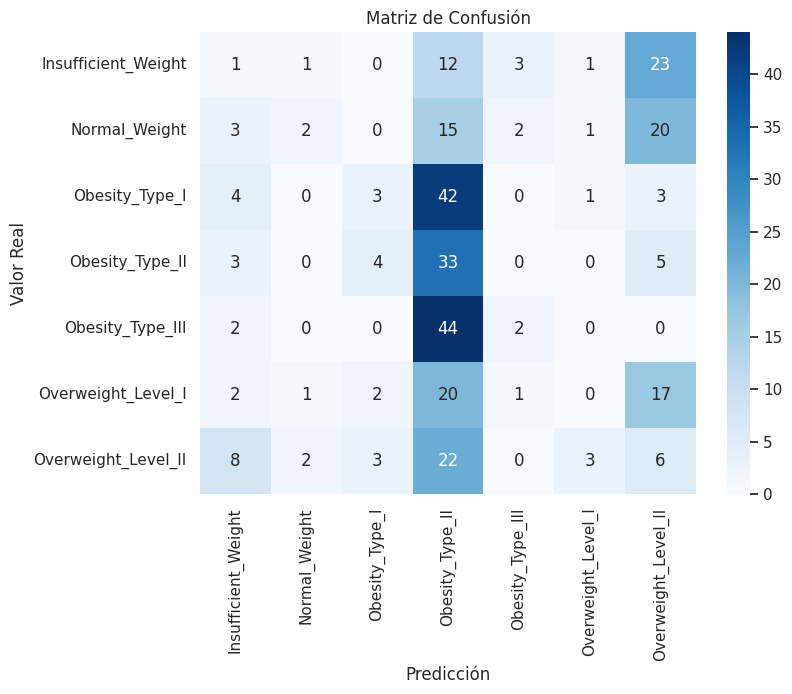

In [ ]:
# @title
# -----------------------------------------------------------------------------
# CONSTRUCCIÓN Y COMPILACIÓN DEL MODELO
# -----------------------------------------------------------------------------
# Definir la arquitectura de la red neuronal de forma secuencial

model = Sequential([
    # Capa de entrada con una forma igual al número de características
    Input(shape=(X_train_scaled.shape[1],)),
    # Primera capa oculta con 64 neuronas y función de activación ReLU
    Dense(64, activation='relu'),
    # Segunda capa oculta con 32 neuronas
    Dense(32, activation='relu'),
    Dense(16, activation='relu'),
    # Capa de salida con una neurona por cada clase y activación Softmax para clasificación
    Dense(num_classes, activation='softmax')
])

# Definir el scheduler de tasa de aprendizaje
initial_learning_rate = 1e-3
lr_schedule = ExponentialDecay(
    initial_learning_rate,
    decay_steps=10000,  # Ajusta según el tamaño de tu dataset y batch size
    decay_rate=0.96,    # Tasa a la que decae la LR
    staircase=True)

# Se modifica el learning rate con el scheduler para el SGD
model.compile(
    optimizer=tf.keras.optimizers.SGD(learning_rate=lr_schedule), # Usamos el scheduler como learning_rate
    loss='categorical_crossentropy',    # Función de pérdida para clasificación multiclase
    metrics=['accuracy']                # Métrica a monitorear durante el entrenamiento
)

# Mostrar un resumen de la arquitectura del modelo
model.summary()
print("Modelo construido y compilado.\n")

# -----------------------------------------------------------------------------
# ENTRENAMIENTO DEL MODELO
# -----------------------------------------------------------------------------
print("--- Entrenamiento del Modelo ---")
# Configurar EarlyStopping para detener el entrenamiento si no hay mejora
early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

# Entrenar el modelo con los datos de entrenamiento
history_3 = model.fit(
    X_train_scaled,
    y_train_cat,
    epochs=10,                     # Número máximo de pasadas por los datos
    batch_size=32,                  # Número de muestras por actualización de gradiente
    validation_split=0.2,           # Porcentaje de datos de entrenamiento para validación
    callbacks=[early_stopping],     # Aplicar el callback de EarlyStopping
    verbose=1                       # Mostrar el progreso del entrenamiento
)

print("Entrenamiento finalizado.\n")

# -----------------------------------------------------------------------------
# EVALUACIÓN DEL MODELO
# -----------------------------------------------------------------------------
print("--- Evaluación del Modelo ---")
# El modelo predice probabilidades para cada clase
y_pred_prob = model.predict(X_test_scaled)

# Convertir las probabilidades a la clase predicha (la de mayor probabilidad)
y_pred = np.argmax(y_pred_prob, axis=1) #[0,0,1] ---> 2

# Generar el reporte de clasificación con las métricas principales
print("Reporte de Clasificación:")
reporte_3 = classification_report(y_test, y_pred)
print(reporte_3)

# Calcular la precisión (accuracy) global
accuracy = accuracy_score(y_test, y_pred)
print(f"Precisión (Accuracy) General: {accuracy:.4f}\n")

# Generar y mostrar la matriz de confusión para visualizar el rendimiento
print("Matriz de Confusión:")
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
# Usar le_y.classes_ para las etiquetas de los ejes de la matriz de confusión
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=le_y.classes_, yticklabels=le_y.classes_)
plt.xlabel('Predicción')
plt.ylabel('Valor Real')
plt.title('Matriz de Confusión')
plt.show()

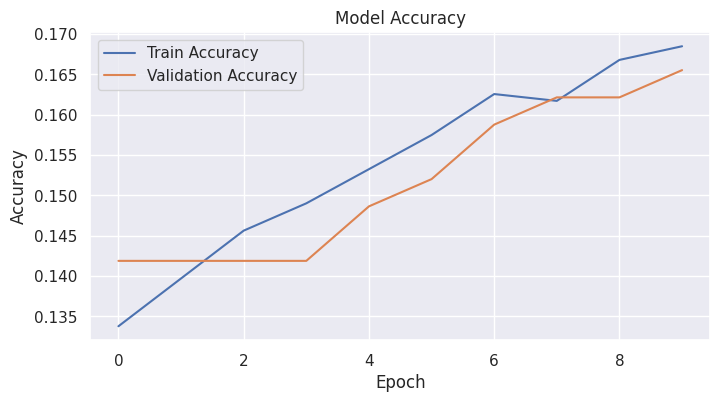

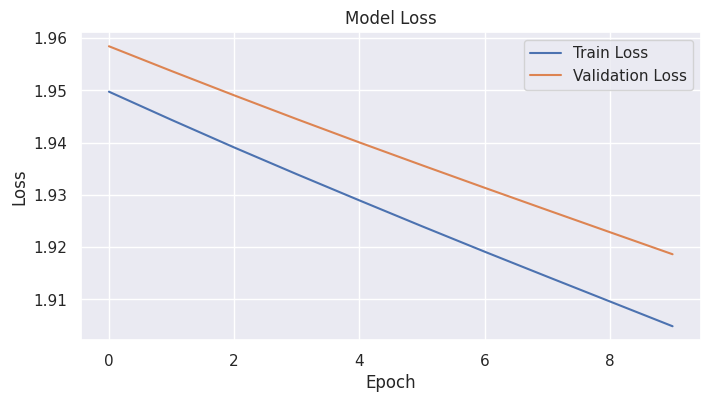

In [ ]:
# @title
# Graficar Accuracy de entrenamiento y validación
plt.figure(figsize=(8, 4))
plt.plot(history_3.history['accuracy'], label='Train Accuracy')
plt.plot(history_3.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

# Graficar Loss de entrenamiento y validación
plt.figure(figsize=(8, 4))
plt.plot(history_3.history['loss'], label='Train Loss')
plt.plot(history_3.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

Model: "sequential_66"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_263 (Dense)               │ (None, 64)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_264 (Dense)               │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_265 (Dense)               │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_266 (Dense)               │ (None, 7)              │           119 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,815 (14.90 KB)

 Trainable params: 3,815 (14.90 KB)

 Non-trainable params: 0 (0.00 B)

Modelo construido y compilado.

--- Entrenamiento del Modelo ---
Epoch 1/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.0791 - loss: 2.0780 - val_accuracy: 0.0912 - val_loss: 2.0769
Epoch 2/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.0667 - loss: 2.0948 - val_accuracy: 0.0878 - val_loss: 2.0680
Epoch 3/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.0823 - loss: 2.0849 - val_accuracy: 0.0946 - val_loss: 2.0597
Epoch 4/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.0819 - loss: 2.0701 - val_accuracy: 0.0946 - val_loss: 2.0520
Epoch 5/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.0872 - loss: 2.0664 - val_accuracy: 0.0980 - val_loss: 2.0449
Epoch 6/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.0847 - loss: 2.0676 - val_accuracy: 0.0946 - val_loss: 2.0383
Epoch 7/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.0925 - loss: 2.0489 - val_accuracy: 0.0946 - val_loss: 2.0322
Epoch 8/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step -

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


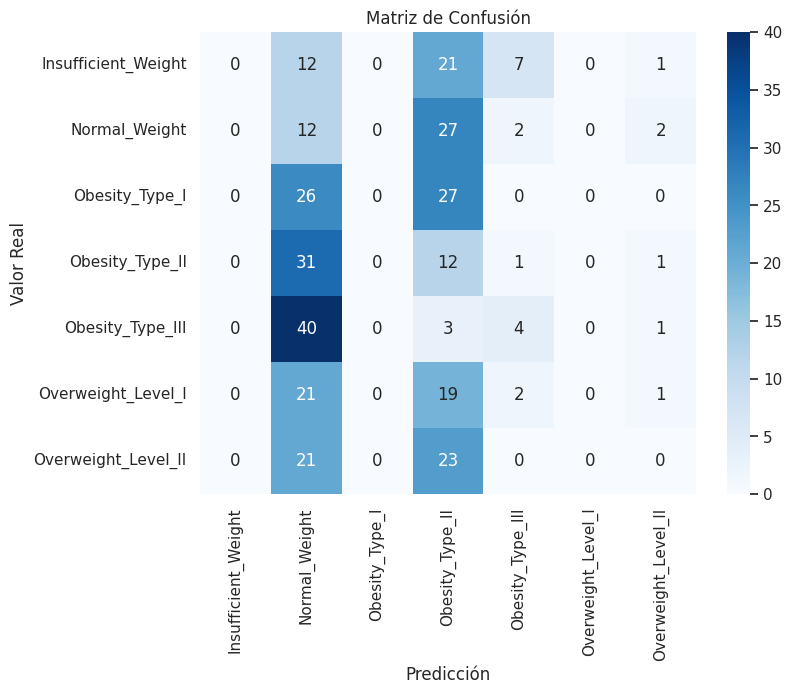

In [ ]:
# @title
# -----------------------------------------------------------------------------
# CONSTRUCCIÓN Y COMPILACIÓN DEL MODELO
# -----------------------------------------------------------------------------
# Definir la arquitectura de la red neuronal de forma secuencial

model = Sequential([
    # Capa de entrada con una forma igual al número de características
    Input(shape=(X_train_scaled.shape[1],)),
    # Primera capa oculta con 64 neuronas y función de activación ReLU
    Dense(64, activation='relu'),
    # Segunda capa oculta con 32 neuronas
    Dense(32, activation='relu'),
    Dense(16, activation='relu'),
    # Capa de salida con una neurona por cada clase y activación Softmax para clasificación
    Dense(num_classes, activation='softmax')
])

# Definir el scheduler de tasa de aprendizaje
initial_learning_rate = 1e-3
lr_schedule = ExponentialDecay(
    initial_learning_rate,
    decay_steps=10000,  # Ajusta según el tamaño de tu dataset y batch size
    decay_rate=0.96,    # Tasa a la que decae la LR
    staircase=True)

# Se modifica el learning rate con el scheduler para el SGD
model.compile(
    optimizer=tf.keras.optimizers.SGD(learning_rate=lr_schedule), # Usamos el scheduler como learning_rate
    loss='categorical_crossentropy',    # Función de pérdida para clasificación multiclase
    metrics=['accuracy']                # Métrica a monitorear durante el entrenamiento
)

# Mostrar un resumen de la arquitectura del modelo
model.summary()
print("Modelo construido y compilado.\n")

# -----------------------------------------------------------------------------
# ENTRENAMIENTO DEL MODELO
# -----------------------------------------------------------------------------
print("--- Entrenamiento del Modelo ---")
# Configurar EarlyStopping para detener el entrenamiento si no hay mejora
early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

# Entrenar el modelo con los datos de entrenamiento. Cambiamos el tamaño del batch
history_4 = model.fit(
    X_train_scaled,
    y_train_cat,
    epochs=10,                     # Número máximo de pasadas por los datos
    batch_size=64,                  # Número de muestras por actualización de gradiente
    validation_split=0.2,           # Porcentaje de datos de entrenamiento para validación
    callbacks=[early_stopping],     # Aplicar el callback de EarlyStopping
    verbose=1                       # Mostrar el progreso del entrenamiento
)

print("Entrenamiento finalizado.\n")

# -----------------------------------------------------------------------------
# EVALUACIÓN DEL MODELO
# -----------------------------------------------------------------------------
print("--- Evaluación del Modelo ---")
# El modelo predice probabilidades para cada clase
y_pred_prob = model.predict(X_test_scaled)

# Convertir las probabilidades a la clase predicha (la de mayor probabilidad)
y_pred = np.argmax(y_pred_prob, axis=1) #[0,0,1] ---> 2

# Generar el reporte de clasificación con las métricas principales
print("Reporte de Clasificación:")
reporte_4 = classification_report(y_test, y_pred)
print(reporte_4)

# Calcular la precisión (accuracy) global
accuracy = accuracy_score(y_test, y_pred)
print(f"Precisión (Accuracy) General: {accuracy:.4f}\n")

# Generar y mostrar la matriz de confusión para visualizar el rendimiento
print("Matriz de Confusión:")
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
# Usar le_y.classes_ para las etiquetas de los ejes de la matriz de confusión
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=le_y.classes_, yticklabels=le_y.classes_)
plt.xlabel('Predicción')
plt.ylabel('Valor Real')
plt.title('Matriz de Confusión')
plt.show()

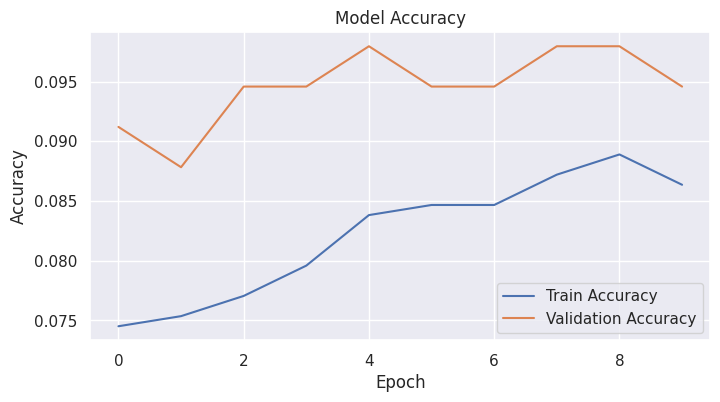

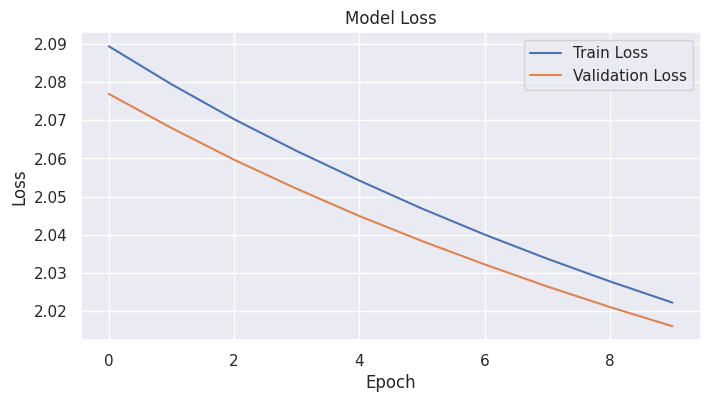

In [ ]:
# @title
# Graficar Accuracy de entrenamiento y validación
plt.figure(figsize=(8, 4))
plt.plot(history_4.history['accuracy'], label='Train Accuracy')
plt.plot(history_4.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

# Graficar Loss de entrenamiento y validación
plt.figure(figsize=(8, 4))
plt.plot(history_4.history['loss'], label='Train Loss')
plt.plot(history_4.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

Model: "sequential_67"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_267 (Dense)               │ (None, 64)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_50 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_268 (Dense)               │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_51 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_269 (Dense)               │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_52 (Dropout)            │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_270 (Dense)               │ (None, 7)              │           119 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,815 (14.90 KB)

 Trainable params: 3,815 (14.90 KB)

 Non-trainable params: 0 (0.00 B)

Modelo construido y compilado.

--- Entrenamiento del Modelo ---
Epoch 1/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.1317 - loss: 2.0288 - val_accuracy: 0.1318 - val_loss: 2.0005
Epoch 2/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.1413 - loss: 2.0120 - val_accuracy: 0.1351 - val_loss: 1.9958
Epoch 3/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.1370 - loss: 2.0299 - val_accuracy: 0.1351 - val_loss: 1.9911
Epoch 4/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.1333 - loss: 2.0280 - val_accuracy: 0.1318 - val_loss: 1.9866
Epoch 5/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.1433 - loss: 2.0223 - val_accuracy: 0.1385 - val_loss: 1.9825
Epoch 6/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.1441 - loss: 2.0254 - val_accuracy: 0.1419 - val_loss: 1.9784
Epoch 7/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.1744 - loss: 1.9994 - val_accuracy: 0.1453 - val_loss: 1.9745
Epoch 8/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - 

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


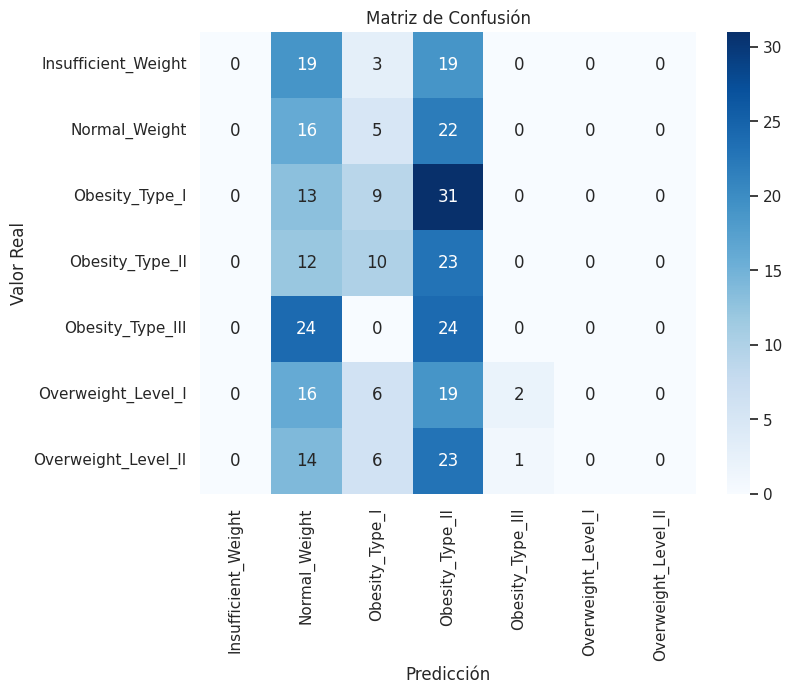

In [ ]:
# @title
# -----------------------------------------------------------------------------
# CONSTRUCCIÓN Y COMPILACIÓN DEL MODELO
# -----------------------------------------------------------------------------
# Definir la arquitectura de la red neuronal de forma secuencial. Se implementa un
# dropout de 0.2

model = Sequential([
    # Capa de entrada con una forma igual al número de características
    Input(shape=(X_train_scaled.shape[1],)),
    # Primera capa oculta con 64 neuronas y función de activación ReLU
    Dense(64, activation='relu'),
    Dropout(0.2), # Añadido Dropout
    # Segunda capa oculta con 32 neuronas
    Dense(32, activation='relu'),
    Dropout(0.2), # Añadido Dropout
    Dense(16, activation='relu'),
    Dropout(0.2), # Añadido Dropout
    # Capa de salida con una neurona por cada clase y activación Softmax para clasificación
    Dense(num_classes, activation='softmax')
])

# Definir el scheduler de tasa de aprendizaje
initial_learning_rate = 1e-3
lr_schedule = ExponentialDecay(
    initial_learning_rate,
    decay_steps=10000,  # Ajusta según el tamaño de tu dataset y batch size
    decay_rate=0.96,    # Tasa a la que decae la LR
    staircase=True)

# Se modifica el learning rate con el scheduler para el SGD
model.compile(
    optimizer=tf.keras.optimizers.SGD(learning_rate=lr_schedule), # Usamos el scheduler como learning_rate
    loss='categorical_crossentropy',    # Función de pérdida para clasificación multiclase
    metrics=['accuracy']                # Métrica a monitorear durante el entrenamiento
)

# Mostrar un resumen de la arquitectura del modelo
model.summary()
print("Modelo construido y compilado.\n")

# -----------------------------------------------------------------------------
# ENTRENAMIENTO DEL MODELO
# -----------------------------------------------------------------------------
print("--- Entrenamiento del Modelo ---")
# Configurar EarlyStopping para detener el entrenamiento si no hay mejora
early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

# Entrenar el modelo con los datos de entrenamiento
history_5 = model.fit(
    X_train_scaled,
    y_train_cat,
    epochs=10,                     # Número máximo de pasadas por los datos
    batch_size=64,                  # Número de muestras por actualización de gradiente
    validation_split=0.2,           # Porcentaje de datos de entrenamiento para validación
    callbacks=[early_stopping],     # Aplicar el callback de EarlyStopping
    verbose=1                       # Mostrar el progreso del entrenamiento
)

print("Entrenamiento finalizado.\n")

# -----------------------------------------------------------------------------
# EVALUACIÓN DEL MODELO
# -----------------------------------------------------------------------------
print("--- Evaluación del Modelo ---")
# El modelo predice probabilidades para cada clase
y_pred_prob = model.predict(X_test_scaled)

# Convertir las probabilidades a la clase predicha (la de mayor probabilidad)
y_pred = np.argmax(y_pred_prob, axis=1) #[0,0,1] ---> 2

# Generar el reporte de clasificación con las métricas principales
print("Reporte de Clasificación:")
reporte_5 = classification_report(y_test, y_pred)
print(reporte_5)

# Calcular la precisión (accuracy) global
accuracy = accuracy_score(y_test, y_pred)
print(f"Precisión (Accuracy) General: {accuracy:.4f}\n")

# Generar y mostrar la matriz de confusión para visualizar el rendimiento
print("Matriz de Confusión:")
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
# Usar le_y.classes_ para las etiquetas de los ejes de la matriz de confusión
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=le_y.classes_, yticklabels=le_y.classes_)
plt.xlabel('Predicción')
plt.ylabel('Valor Real')
plt.title('Matriz de Confusión')
plt.show()

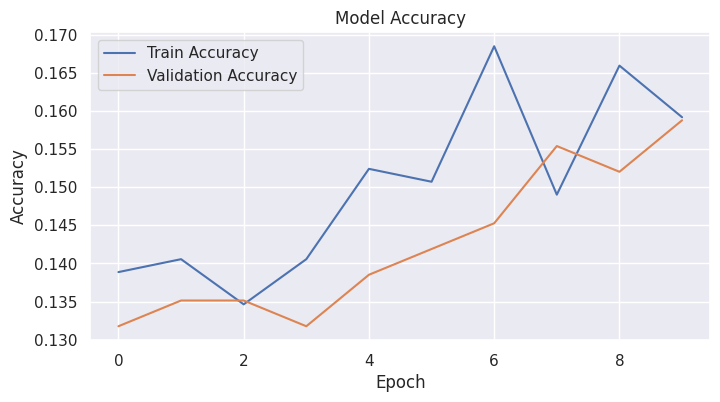

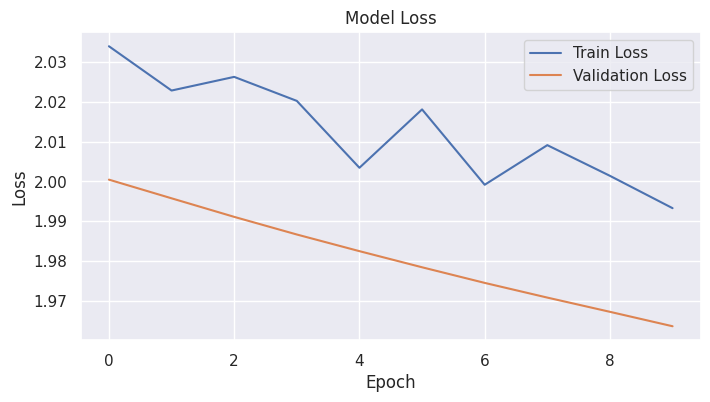

In [ ]:
# @title
# Graficar Accuracy de entrenamiento y validación
plt.figure(figsize=(8, 4))
plt.plot(history_5.history['accuracy'], label='Train Accuracy')
plt.plot(history_5.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

# Graficar Loss de entrenamiento y validación
plt.figure(figsize=(8, 4))
plt.plot(history_5.history['loss'], label='Train Loss')
plt.plot(history_5.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

Model: "sequential_68"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_271 (Dense)               │ (None, 64)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_53 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_272 (Dense)               │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_54 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_273 (Dense)               │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_55 (Dropout)            │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_274 (Dense)               │ (None, 7)              │           119 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,815 (14.90 KB)

 Trainable params: 3,815 (14.90 KB)

 Non-trainable params: 0 (0.00 B)

Modelo construido y compilado.

--- Entrenamiento del Modelo ---
Epoch 1/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.1129 - loss: 2.3287 - val_accuracy: 0.1419 - val_loss: 2.0578
Epoch 2/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.1436 - loss: 2.2583 - val_accuracy: 0.1486 - val_loss: 2.0489
Epoch 3/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.1225 - loss: 2.2943 - val_accuracy: 0.1486 - val_loss: 2.0401
Epoch 4/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.1387 - loss: 2.2288 - val_accuracy: 0.1486 - val_loss: 2.0323
Epoch 5/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.1372 - loss: 2.2525 - val_accuracy: 0.1419 - val_loss: 2.0246
Epoch 6/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.1154 - loss: 2.2771 - val_accuracy: 0.1419 - val_loss: 2.0175
Epoch 7/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.1254 - loss: 2.2450 - val_accuracy: 0.1385 - val_loss: 2.0113
Epoch 8/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - 

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


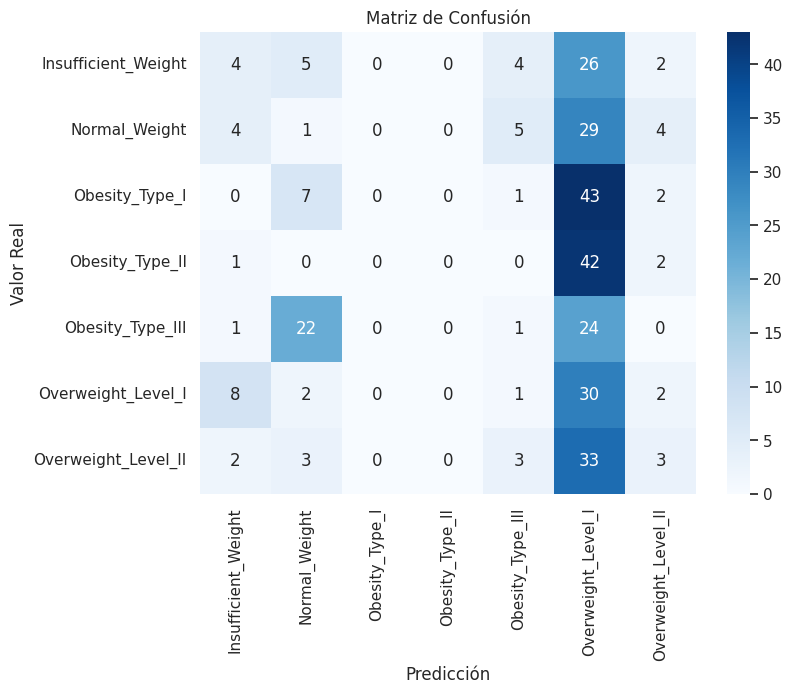

In [ ]:
# @title
# -----------------------------------------------------------------------------
# CONSTRUCCIÓN Y COMPILACIÓN DEL MODELO
# -----------------------------------------------------------------------------
# Definir la arquitectura de la red neuronal de forma secuencial. Se implementa un
# dropout de 0.4

model = Sequential([
    # Capa de entrada con una forma igual al número de características
    Input(shape=(X_train_scaled.shape[1],)),
    # Primera capa oculta con 64 neuronas y función de activación ReLU
    Dense(64, activation='relu'),
    Dropout(0.4), # Añadido Dropout
    # Segunda capa oculta con 32 neuronas
    Dense(32, activation='relu'),
    Dropout(0.4), # Añadido Dropout
    Dense(16, activation='relu'),
    Dropout(0.4), # Añadido Dropout
    # Capa de salida con una neurona por cada clase y activación Softmax para clasificación
    Dense(num_classes, activation='softmax')
])

# Definir el scheduler de tasa de aprendizaje
initial_learning_rate = 1e-3
lr_schedule = ExponentialDecay(
    initial_learning_rate,
    decay_steps=10000,  # Ajusta según el tamaño de tu dataset y batch size
    decay_rate=0.96,    # Tasa a la que decae la LR
    staircase=True)

# Se modifica el learning rate con el scheduler para el SGD
model.compile(
    optimizer=tf.keras.optimizers.SGD(learning_rate=lr_schedule), # Usamos el scheduler como learning_rate
    loss='categorical_crossentropy',    # Función de pérdida para clasificación multiclase
    metrics=['accuracy']                # Métrica a monitorear durante el entrenamiento
)

# Mostrar un resumen de la arquitectura del modelo
model.summary()
print("Modelo construido y compilado.\n")

# -----------------------------------------------------------------------------
# ENTRENAMIENTO DEL MODELO
# -----------------------------------------------------------------------------
print("--- Entrenamiento del Modelo ---")
# Configurar EarlyStopping para detener el entrenamiento si no hay mejora
early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

# Entrenar el modelo con los datos de entrenamiento
history_6 = model.fit(
    X_train_scaled,
    y_train_cat,
    epochs=10,                     # Número máximo de pasadas por los datos
    batch_size=64,                  # Número de muestras por actualización de gradiente
    validation_split=0.2,           # Porcentaje de datos de entrenamiento para validación
    callbacks=[early_stopping],     # Aplicar el callback de EarlyStopping
    verbose=1                       # Mostrar el progreso del entrenamiento
)

print("Entrenamiento finalizado.\n")

# -----------------------------------------------------------------------------
# EVALUACIÓN DEL MODELO
# -----------------------------------------------------------------------------
print("--- Evaluación del Modelo ---")
# El modelo predice probabilidades para cada clase
y_pred_prob = model.predict(X_test_scaled)

# Convertir las probabilidades a la clase predicha (la de mayor probabilidad)
y_pred = np.argmax(y_pred_prob, axis=1) #[0,0,1] ---> 2

# Generar el reporte de clasificación con las métricas principales
print("Reporte de Clasificación:")
reporte_6 = classification_report(y_test, y_pred)
print(reporte_6)

# Calcular la precisión (accuracy) global
accuracy = accuracy_score(y_test, y_pred)
print(f"Precisión (Accuracy) General: {accuracy:.4f}\n")

# Generar y mostrar la matriz de confusión para visualizar el rendimiento
print("Matriz de Confusión:")
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
# Usar le_y.classes_ para las etiquetas de los ejes de la matriz de confusión
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=le_y.classes_, yticklabels=le_y.classes_)
plt.xlabel('Predicción')
plt.ylabel('Valor Real')
plt.title('Matriz de Confusión')
plt.show()

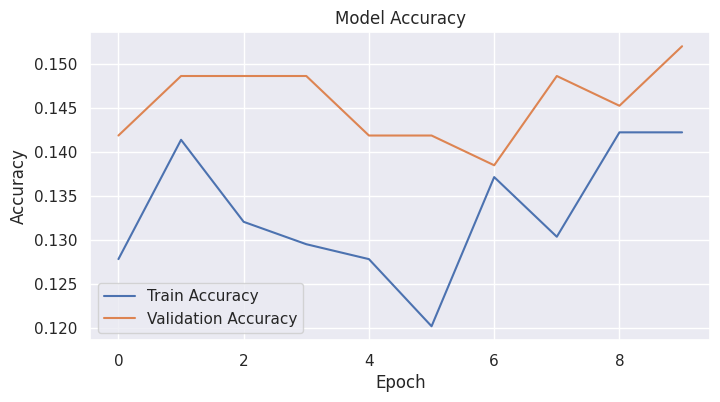

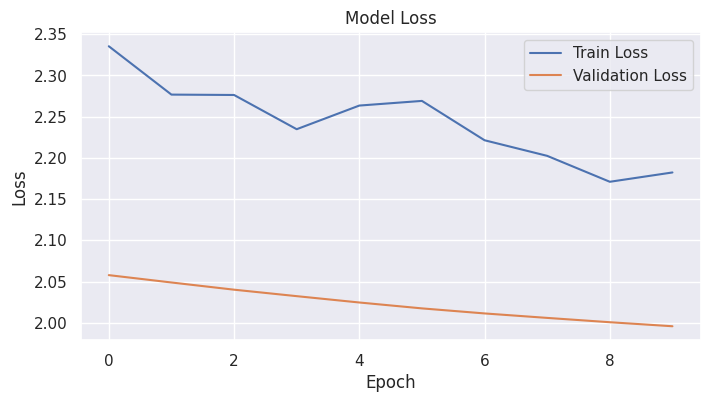

In [ ]:
# @title
# Graficar Accuracy de entrenamiento y validación
plt.figure(figsize=(8, 4))
plt.plot(history_6.history['accuracy'], label='Train Accuracy')
plt.plot(history_6.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

# Graficar Loss de entrenamiento y validación
plt.figure(figsize=(8, 4))
plt.plot(history_6.history['loss'], label='Train Loss')
plt.plot(history_6.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

Model: "sequential_69"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_275 (Dense)               │ (None, 64)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_276 (Dense)               │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_277 (Dense)               │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_278 (Dense)               │ (None, 7)              │           119 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,815 (14.90 KB)

 Trainable params: 3,815 (14.90 KB)

 Non-trainable params: 0 (0.00 B)

Modelo construido y compilado.

--- Entrenamiento del Modelo ---
Epoch 1/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.3576 - loss: 1.7585 - val_accuracy: 0.5777 - val_loss: 1.1746
Epoch 2/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6251 - loss: 1.0152 - val_accuracy: 0.6757 - val_loss: 0.8312
Epoch 3/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7792 - loss: 0.6756 - val_accuracy: 0.7061 - val_loss: 0.6847
Epoch 4/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8115 - loss: 0.5327 - val_accuracy: 0.8209 - val_loss: 0.5142
Epoch 5/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8431 - loss: 0.4247 - val_accuracy: 0.8074 - val_loss: 0.4644
Epoch 6/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8966 - loss: 0.2926 - val_accuracy: 0.9122 - val_loss: 0.3437
Epoch 7/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9381 - loss: 0.2273 - val_accuracy: 0.8615 - val_loss: 0.3463
Epoch 8/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - 

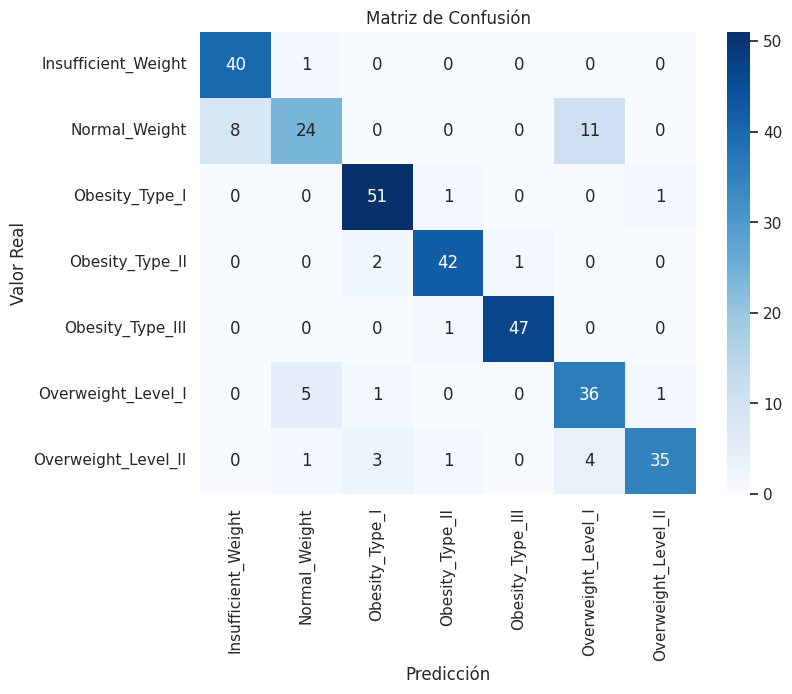

In [ ]:
# -----------------------------------------------------------------------------
# CONSTRUCCIÓN Y COMPILACIÓN DEL MODELO
# -----------------------------------------------------------------------------
# Definir la arquitectura de la red neuronal de forma secuencial. Se implementa un
# dropout de 0.4

model = Sequential([
    # Capa de entrada con una forma igual al número de características
    Input(shape=(X_train_scaled.shape[1],)),
    # Primera capa oculta con 64 neuronas y función de activación ReLU
    Dense(64, activation='relu'),
    # Segunda capa oculta con 32 neuronas
    Dense(32, activation='relu'),
    # Tercera capa oculta con 16 neuronas
    Dense(16, activation='relu'),
    # Capa de salida con una neurona por cada clase y activación Softmax para clasificación
    Dense(num_classes, activation='softmax')
])

initial_learning_rate = 1e-1
lr_schedule = ExponentialDecay(
    initial_learning_rate,
    decay_steps=1000,  # Ajusta según el tamaño de tu dataset y batch size
    decay_rate=0.96,    # Tasa a la que decae la LR
    staircase=True)


# Se modifica el learning rate con el scheduler para el SGD
model.compile(
    optimizer=tf.keras.optimizers.SGD(learning_rate=lr_schedule), # Usamos el scheduler como learning_rate
    loss='categorical_crossentropy',    # Función de pérdida para clasificación multiclase
    metrics=['accuracy']                # Métrica a monitorear durante el entrenamiento
)

# Mostrar un resumen de la arquitectura del modelo
model.summary()
print("Modelo construido y compilado.\n")

# -----------------------------------------------------------------------------
# ENTRENAMIENTO DEL MODELO
# -----------------------------------------------------------------------------
print("--- Entrenamiento del Modelo ---")
# Configurar EarlyStopping para detener el entrenamiento si no hay mejora
early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

# Entrenar el modelo con los datos de entrenamiento
history_7 = model.fit(
    X_train_scaled,
    y_train_cat,
    epochs=10,                     # Número máximo de pasadas por los datos
    batch_size=32,                  # Número de muestras por actualización de gradiente
    validation_split=0.2,           # Porcentaje de datos de entrenamiento para validación
    callbacks=[early_stopping],     # Aplicar el callback de EarlyStopping
    verbose=1                       # Mostrar el progreso del entrenamiento
)

print("Entrenamiento finalizado.\n")

# -----------------------------------------------------------------------------
# EVALUACIÓN DEL MODELO
# -----------------------------------------------------------------------------
print("--- Evaluación del Modelo ---")
# El modelo predice probabilidades para cada clase
y_pred_prob = model.predict(X_test_scaled)

# Convertir las probabilidades a la clase predicha (la de mayor probabilidad)
y_pred = np.argmax(y_pred_prob, axis=1) #[0,0,1] ---> 2

# Generar el reporte de clasificación con las métricas principales
print("Reporte de Clasificación:")
reporte_7 = classification_report(y_test, y_pred)
print(reporte_7)

# Calcular la precisión (accuracy) global
accuracy = accuracy_score(y_test, y_pred)
print(f"Precisión (Accuracy) General: {accuracy:.4f}\n")

# Generar y mostrar la matriz de confusión para visualizar el rendimiento
print("Matriz de Confusión:")
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
# Usar le_y.classes_ para las etiquetas de los ejes de la matriz de confusión
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=le_y.classes_, yticklabels=le_y.classes_)
plt.xlabel('Predicción')
plt.ylabel('Valor Real')
plt.title('Matriz de Confusión')
plt.show()

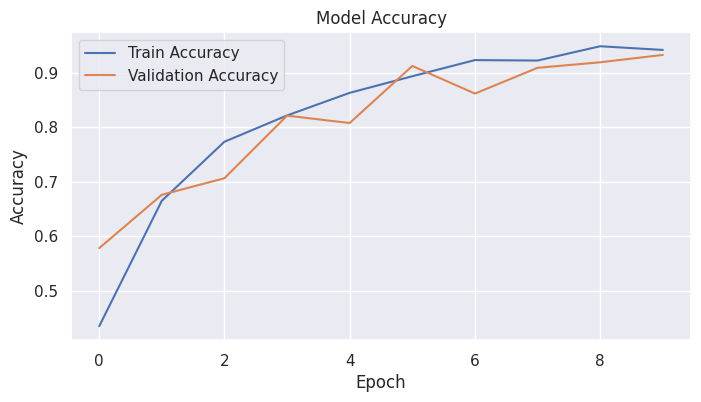

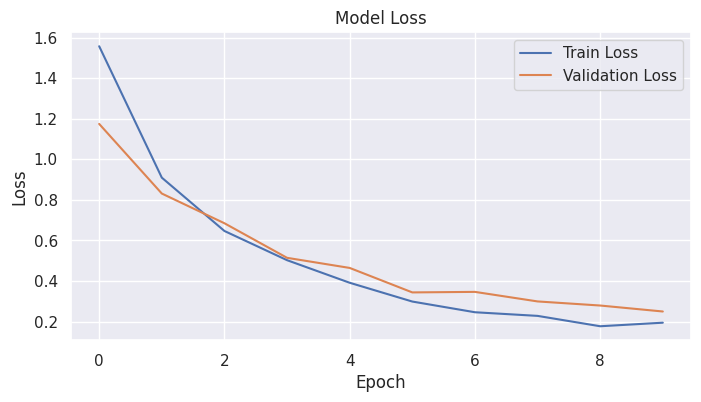

In [ ]:
# Graficar Accuracy de entrenamiento y validación
plt.figure(figsize=(8, 4))
plt.plot(history_7.history['accuracy'], label='Train Accuracy')
plt.plot(history_7.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

# Graficar Loss de entrenamiento y validación
plt.figure(figsize=(8, 4))
plt.plot(history_7.history['loss'], label='Train Loss')
plt.plot(history_7.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

### **Experimentación y análisis**

**Preguntas para el análisis y experimentación**

- Compara el rendimiento de las diferentes configuraciones probadas en el conjunto de validación. ¿Qué combinación de hiperparámetros y estrategias funcionó mejor?
- Analiza las curvas de entrenamiento (pérdida y métricas) para cada experimento. ¿Observas sobreajuste en alguna configuración? ¿Ayudó `EarlyStopping` a mitigarlo?
- ¿Cómo se compara el rendimiento del mejor modelo de red neuronal con el mejor clasificador tradicional del Ejercicio 1 en el conjunto de prueba?
- Considerando las matrices de confusión, ¿la red neuronal tiene problemas similares con ciertas clases que los modelos tradicionales?

# Respuestas
* Las estrategia que mejor funcionó fueron aquellas que tuvieron una Learning Rate alta (i.e. 1e-1, 1e-2), tanto para SGD como para Adam. El accuracy para ambos casos fue 0.88 y 0.90 respectivamente.
* En varias combinaciones hubo sobreajuste, sobre todo en aquellas con velocidades bajas (menores a 1e-3). En este caso, el `EarlyStopping` no mitigó el sobreajuste debido a que la paciencia era igual al número máximo de épocas definido, por tanto la probabilidad de cumplir la condición para parar el entrenamiento era muy baja
* En este caso, dadas las configuraciones de la red, el desempeño fue menor al mejor modelo tradicional. La red neuronal que mejor se comportó fue una compilada con optimizador Adam, LR=1e-2, Batch size=32, sin dropouts, el cual obtuvo un **Accuracy de 0.90**, sin embargo, el RandomForest del Ejercicio 1 obtuvo un **Accuracy de 0.93** para el conjunto de prueba.
* Así es. Aparentemente, la red neuronal tiene problemas para clasificar aquellas etiquetas que tienen un menor número de muestras en el conjunto de datos, al igual que los modelos tradicionales.

## Ejercicio 3 — Regresión con Redes Neuronales (Bike Sharing Demand)

**Objetivo:** modelar la **demanda diaria de bicicletas** en función de factores ambientales y temporales.
- Carga por URL: `https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset` (usaremos el archivo `day.csv` dentro del zip).
- División train/val/test.
- Preprocesamiento de variables categóricas (One-Hot Encoding).
- Estandarización de características numéricas.
- MLP para regresión (`mse`), con **EarlyStopping**.
- Métricas: **MAE**, **MSE**, **R²**.

### Actividad - Ejercicio 3: Regresión con Redes Neuronales (Bike Sharing Demand)

Basado en el código proporcionado, realiza las siguientes tareas:

1.  **Revisión del código**: Familiarízate con el código que carga, preprocesa, divide el dataset Bike Sharing Demand, y construye/entrena/evalúa la red neuronal para regresión.
2.  **Experimentación con la Arquitectura y Hiperparámetros de la NN**:
    *   Modifica la arquitectura de la red neuronal en la celda de construcción del modelo (`Cyoi8QaXZS50`):
        *   Cambia el número de capas densas o el número de neuronas en cada capa.
        *   Experimenta con la tasa de dropout.
    *   Modifica los hiperparámetros de entrenamiento:
        *   Prueba diferentes tasas de aprendizaje para el optimizador Adam.
        *   Cambia el tamaño del batch (`batch_size`).
        *   Ajusta la paciencia del `EarlyStopping`.
    *   Entrena el modelo con diferentes combinaciones y observa las curvas de entrenamiento y las métricas en validación.
3.  **Modificación de Características de Entrenamiento**:
    *   Vuelve a la celda de preparación de datos (`741c505b`) y experimenta con las características utilizadas:
        *   Incluye o excluye algunas características originales (`season`, `yr`, `mnth`, `holiday`, `weekday`, `workingday`, `weathersit`, `temp`, `atemp`, `hum`, `windspeed`). Por ejemplo, podrías probar a quitar `atemp` o `windspeed`.
        *   Considera si alguna de las características categóricas (`season`, `yr`, `mnth`, etc.) debería ser tratada de forma diferente o si incluir/excluir alguna combinación de ellas impacta el resultado.
    *   Vuelve a entrenar y evaluar el modelo con el nuevo conjunto de características y compara los resultados (MAE, MSE, R²).
4.  **Análisis de Resultados**:
    *   Compara el rendimiento (MAE, MSE, R²) de las diferentes configuraciones de la red neuronal y las diferentes selecciones de características en el conjunto de prueba. ¿Qué combinación funcionó mejor?
    *   Analiza las curvas de entrenamiento. ¿Hay signos de sobreajuste o subajuste en alguna configuración?
    *   ¿Qué características crees que son más importantes para predecir la demanda de bicicletas basándote en tus experimentos?
    *   ¿Cómo se compara el rendimiento de la red neuronal para regresión con lo que esperarías de un modelo tradicional en este problema?

### **Cargar el conjunto de datos**

In [ ]:
# Dataset de Regresión: Bike Sharing Demand
reg_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00275/Bike-Sharing-Dataset.zip"

# Como es un zip, descargamos y leemos el csv (day.csv es el que usaremos)
import requests
import zipfile
import io

r = requests.get(reg_url)
z = zipfile.ZipFile(io.BytesIO(r.content))
df_reg = pd.read_csv(z.open('day.csv'))

print(df_reg.shape)
df_reg.head()

(731, 16)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [ ]:
# El dataset Bike Sharing Demand ya ha sido cargado en df_reg

# Las columnas relevantes para la regresión son (basado en la descripción del dataset):
# 'instant' - record index
# 'dteday' - date
# 'season' - 1: winter, 2: spring, 3: summer, 4: fall
# 'yr' - year (0: 2011, 1: 2012)
# 'mnth' - month (1 to 12)
# 'hr' - hour (0 to 23) - NOT available in day.csv
# 'holiday' - weather day is holiday or holiday
# 'weekday' - day of the week
# 'workingday' - if day is neither weekend nor holiday
# 'weathersit' - 1: Clear, Few clouds, Partly cloudy, Partly cloudy
#                2: Mist + Cloudy, Mist + Broken clouds, Mist + Few clouds, Mist
#                3: Light Snow, Light Rain + Thunderstorm + Scattered clouds, Light Rain + Scattered clouds
#                4: Heavy Rain + Ice Pallets + Thunderstorm + Mist, Snow + Fog
# 'temp' - Normalized temperature in Celsius.
# 'atemp' - Normalized feeling temperature in Celsius.
# 'hum' - Normalized humidity.
# 'windspeed' - Normalized wind speed.
# 'casual' - count of casual users
# 'registered' - count of registered users
# 'cnt' - count of total rental bikes including both casual and registered (TARGET)

# Para este ejercicio de regresión con datos diarios (day.csv), usaremos las siguientes características:
features_reg = ['season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday',
                'weathersit', 'temp', 'atemp', 'hum', 'windspeed']
target_reg = 'cnt' # Total rental bikes

Xr = df_reg[features_reg]
yr = df_reg[target_reg]

# --- Bloque 1: Preparación y Partición de los datos ---
print("--- Preparación y Partición de los datos ---")
# Para las características categóricas en Xr, aplicaremos One-Hot Encoding
Xr = pd.get_dummies(Xr, columns=['season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit'], drop_first=True)


Xr_train, Xr_temp, yr_train, yr_temp = train_test_split(Xr, yr, test_size=0.3, random_state=42)
Xr_valid, Xr_test, yr_valid, yr_test = train_test_split(Xr_temp, yr_temp, test_size=0.5, random_state=42)

scaler_r = StandardScaler()
Xr_train_s = scaler_r.fit_transform(Xr_train)
Xr_valid_s = scaler_r.transform(Xr_valid)
Xr_test_s  = scaler_r.transform(Xr_test)

print("Dimensiones de los conjuntos de datos de regresión después de OHE y escalado:")
print(f"Entrenamiento: {Xr_train_s.shape}")
print(f"Validación:    {Xr_valid_s.shape}")
print(f"Prueba:        {Xr_test_s.shape}")
print("-" * 40)

--- Preparación y Partición de los datos ---
Dimensiones de los conjuntos de datos de regresión después de OHE y escalado:
Entrenamiento: (511, 29)
Validación:    (110, 29)
Prueba:        (110, 29)
----------------------------------------


### **Compilación y entrenamiento del modelo**

--- Construcción y Compilación del Modelo ---


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │         7,680 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 40,705 (159.00 KB)

 Trainable params: 40,705 (159.00 KB)

 Non-trainable params: 0 (0.00 B)

Modelo construido y compilado.
----------------------------------------
--- Entrenamiento del Modelo ---
Epoch 1/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 61ms/step - loss: 23502116.0000 - mae: 4466.9224 - mse: 23502116.0000 - r2_score: -5.6500 - root_mean_squared_error: 4846.4873 - val_loss: 23097404.0000 - val_mae: 4351.9888 - val_mse: 23097404.0000 - val_r2_score: -4.5563 - val_root_mean_squared_error: 4805.9761
Epoch 2/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 24810670.0000 - mae: 4623.5396 - mse: 24810670.0000 - r2_score: -6.3167 - root_mean_squared_error: 4980.2852 - val_loss: 23064706.0000 - val_mae: 4348.2754 - val_mse: 23064706.0000 - val_r2_score: -4.5485 - val_root_mean_squared_error: 4802.5728
Epoch 3/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 23979444.0000 - mae: 4519.9844 - mse: 23979444.0000 - r2_score: -5.7843 - root_mean_squared_error: 4896.1772 - val_loss: 23019352.0000 - val_mae: 4343.2607 - val_mse: 23019352.0000 - val_r2_score: -4.5376 - val_root_mean_squared_err

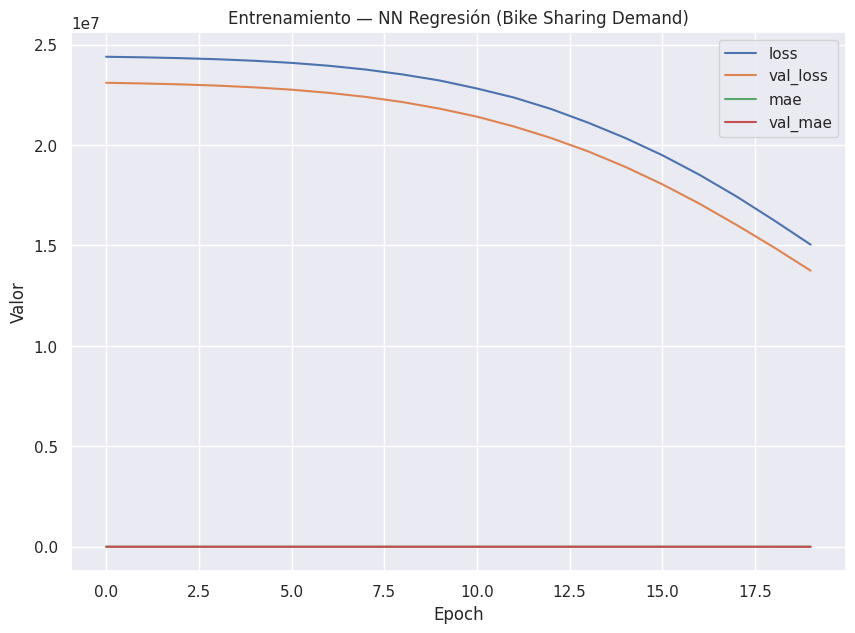

----------------------------------------
--- Evaluación del Modelo ---
Métricas de evaluación en el conjunto de prueba:
MAE:  3380.598
RMSE: 13754765.000
R^2:  -2.620
----------------------------------------


In [ ]:
# --- Bloque 2: Construcción y Compilación del Modelo ---
print("--- Construcción y Compilación del Modelo ---")
tf.keras.backend.clear_session()

# Definir la arquitectura de la red neuronal para regresión
reg_model = keras.Sequential([
    layers.Input(shape=(Xr_train_s.shape[1],)),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.1),
    layers.Dense(128, activation='relu'),
    layers.Dense(1, activation='linear') # Capa de salida lineal para regresión
])

# Compilar el modelo
reg_model.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss='mse', # Función de pérdida para regresión
    metrics=['mae', 'mse', tf.keras.metrics.RootMeanSquaredError(), tf.keras.metrics.R2Score()] # Métricas relevantes
)

reg_model.summary()
print("Modelo construido y compilado.")
print("-" * 40)


# --- Bloque 3: Entrenamiento del Modelo ---
print("--- Entrenamiento del Modelo ---")
# Definimos EarlyStopping con paciencia ajustada para este dataset
es = keras.callbacks.EarlyStopping(monitor='val_loss', patience=30, restore_best_weights=True)

# Entrenamos el modelo de regresión
hist_r = reg_model.fit(
    Xr_train_s, yr_train,
    validation_data=(Xr_valid_s, yr_valid),
    epochs=20, # Aumentamos las epochs ya que EarlyStopping lo detendrá
    batch_size=64,
    verbose=1, # Poner en 1 para ver el progreso
    callbacks=[es]
)

print("Entrenamiento finalizado.")
print("-" * 40)

# Visualizamos las curvas de entrenamiento (MAE y Loss)
print("--- Curvas de Entrenamiento ---")
pd.DataFrame(hist_r.history)[["loss","val_loss","mae","val_mae"]].plot(figsize=(10,7))
plt.title("Entrenamiento — NN Regresión (Bike Sharing Demand)")
plt.xlabel("Epoch")
plt.ylabel("Valor")
plt.grid(True)
plt.show()
print("-" * 40)


# --- Bloque 4: Evaluación del Modelo ---
print("--- Evaluación del Modelo ---")
# Evaluación en el conjunto de prueba
pred_test = reg_model.predict(Xr_test_s, verbose=0).ravel()

# Calculamos las métricas de evaluación
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(yr_test, pred_test)
mse = mean_squared_error(yr_test, pred_test) # squared=False para MSE
r2 = r2_score(yr_test, pred_test)


print(f"Métricas de evaluación en el conjunto de prueba:")
print(f"MAE:  {mae:.3f}")
print(f"RMSE: {mse:.3f}")
print(f"R^2:  {r2:.3f}")
print("-" * 40)

--- Construcción y Compilación del Modelo ---


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │         7,680 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 48,897 (191.00 KB)

 Trainable params: 48,897 (191.00 KB)

 Non-trainable params: 0 (0.00 B)

Modelo construido y compilado.
----------------------------------------
--- Entrenamiento del Modelo ---
Epoch 1/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 64ms/step - loss: 24758040.0000 - mae: 4614.8711 - mse: 24758040.0000 - r2_score: -6.2049 - root_mean_squared_error: 4975.4810 - val_loss: 23099230.0000 - val_mae: 4352.3340 - val_mse: 23099230.0000 - val_r2_score: -4.5568 - val_root_mean_squared_error: 4806.1660
Epoch 2/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 24342502.0000 - mae: 4560.9399 - mse: 24342502.0000 - r2_score: -5.8921 - root_mean_squared_error: 4933.3345 - val_loss: 23053456.0000 - val_mae: 4347.2271 - val_mse: 23053456.0000 - val_r2_score: -4.5458 - val_root_mean_squared_error: 4801.4014
Epoch 3/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 24370994.0000 - mae: 4572.4541 - mse: 24370994.0000 - r2_score: -6.0740 - root_mean_squared_error: 4936.4600 - val_loss: 22961552.0000 - val_mae: 4337.1406 - val_mse: 22961552.0000 - val_r2_score: -4.5237 - val_root_mean_squared_err

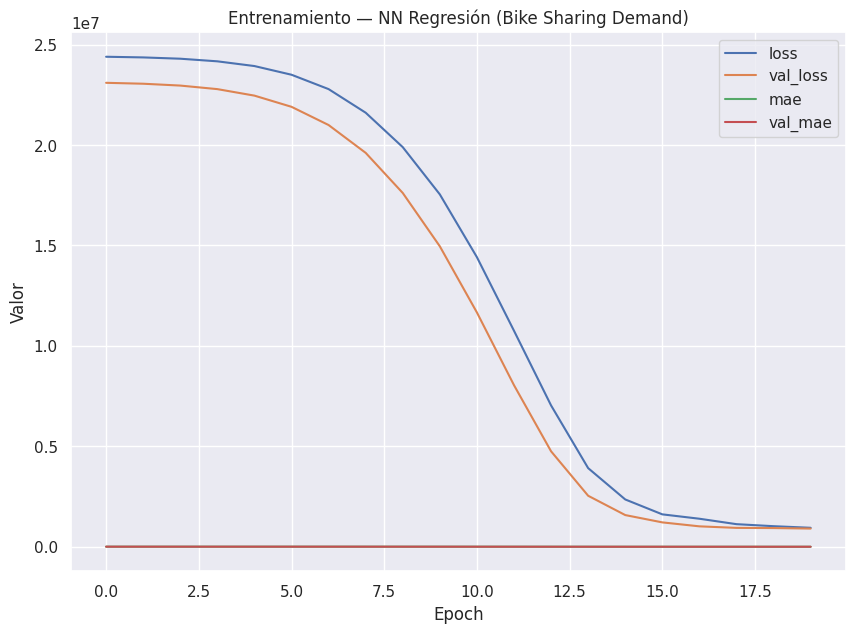

----------------------------------------
--- Evaluación del Modelo ---
Métricas de evaluación en el conjunto de prueba:
MAE:  697.474
RMSE: 773003.375
R^2:  0.797
----------------------------------------


In [ ]:
# --- Bloque 2: Construcción y Compilación del Modelo ---
print("--- Construcción y Compilación del Modelo ---")
tf.keras.backend.clear_session()

# Definir la arquitectura de la red neuronal para regresión
# Aumentamos el numero de neuronas y el valor de dropout
reg_model = keras.Sequential([
    layers.Input(shape=(Xr_train_s.shape[1],)),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='linear') # Capa de salida lineal para regresión
])

# Compilar el modelo
reg_model.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss='mse', # Función de pérdida para regresión
    metrics=['mae', 'mse', tf.keras.metrics.RootMeanSquaredError(), tf.keras.metrics.R2Score()] # Métricas relevantes
)

reg_model.summary()
print("Modelo construido y compilado.")
print("-" * 40)


# --- Bloque 3: Entrenamiento del Modelo ---
print("--- Entrenamiento del Modelo ---")
# Definimos EarlyStopping con paciencia ajustada para este dataset
es = keras.callbacks.EarlyStopping(monitor='val_loss', patience=30, restore_best_weights=True)

# Entrenamos el modelo de regresión
hist_r = reg_model.fit(
    Xr_train_s, yr_train,
    validation_data=(Xr_valid_s, yr_valid),
    epochs=20, # Aumentamos las epochs ya que EarlyStopping lo detendrá
    batch_size=64,
    verbose=1, # Poner en 1 para ver el progreso
    callbacks=[es]
)

print("Entrenamiento finalizado.")
print("-" * 40)

# Visualizamos las curvas de entrenamiento (MAE y Loss)
print("--- Curvas de Entrenamiento ---")
pd.DataFrame(hist_r.history)[["loss","val_loss","mae","val_mae"]].plot(figsize=(10,7))
plt.title("Entrenamiento — NN Regresión (Bike Sharing Demand)")
plt.xlabel("Epoch")
plt.ylabel("Valor")
plt.grid(True)
plt.show()
print("-" * 40)


# --- Bloque 4: Evaluación del Modelo ---
print("--- Evaluación del Modelo ---")
# Evaluación en el conjunto de prueba
pred_test = reg_model.predict(Xr_test_s, verbose=0).ravel()

# Calculamos las métricas de evaluación
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(yr_test, pred_test)
mse = mean_squared_error(yr_test, pred_test) # squared=False para MSE
r2 = r2_score(yr_test, pred_test)


print(f"Métricas de evaluación en el conjunto de prueba:")
print(f"MAE:  {mae:.3f}")
print(f"RMSE: {mse:.3f}")
print(f"R^2:  {r2:.3f}")
print("-" * 40)

--- Construcción y Compilación del Modelo ---


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │         7,680 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 40,705 (159.00 KB)

 Trainable params: 40,705 (159.00 KB)

 Non-trainable params: 0 (0.00 B)

Modelo construido y compilado.
----------------------------------------
--- Entrenamiento del Modelo ---
Epoch 1/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 59ms/step - loss: 23549488.0000 - mae: 4439.1304 - mse: 23549488.0000 - r2_score: -5.1626 - root_mean_squared_error: 4851.4561 - val_loss: 22446322.0000 - val_mae: 4285.4229 - val_mse: 22446322.0000 - val_r2_score: -4.3997 - val_root_mean_squared_error: 4737.7549
Epoch 2/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 22407418.0000 - mae: 4334.3271 - mse: 22407418.0000 - r2_score: -5.0151 - root_mean_squared_error: 4731.0195 - val_loss: 19777066.0000 - val_mae: 4017.3652 - val_mse: 19777068.0000 - val_r2_score: -3.7576 - val_root_mean_squared_error: 4447.1416
Epoch 3/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 19876082.0000 - mae: 4088.0884 - mse: 19876082.0000 - r2_score: -4.3172 - root_mean_squared_error: 4455.3101 - val_loss: 13465991.0000 - val_mae: 3300.3289 - val_mse: 13465991.0000 - val_r2_score: -2.2394 - val_root_mean_squared_err

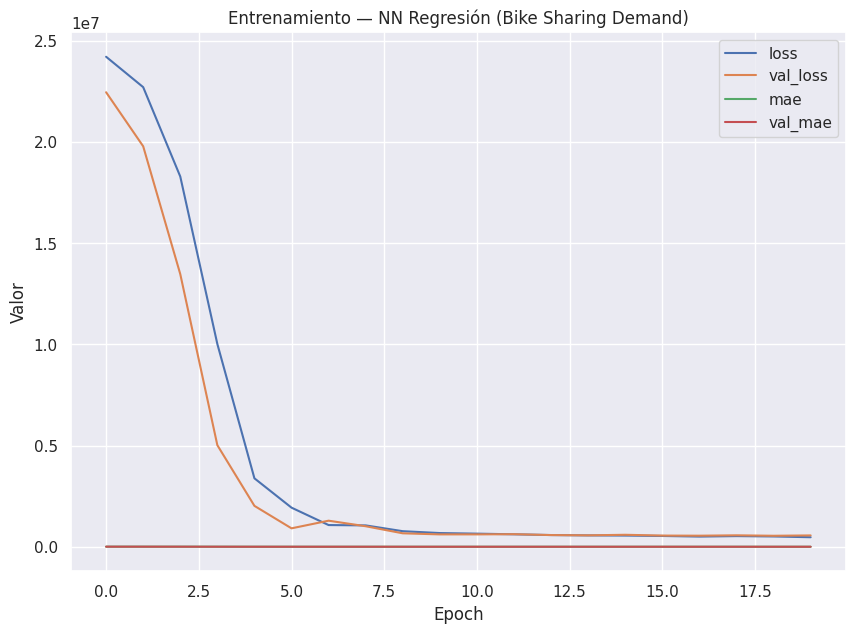

----------------------------------------
--- Evaluación del Modelo ---
Métricas de evaluación en el conjunto de prueba:
MAE:  607.341
RMSE: 583125.750
R^2:  0.847
----------------------------------------


In [ ]:
# --- Bloque 2: Construcción y Compilación del Modelo ---
print("--- Construcción y Compilación del Modelo ---")
tf.keras.backend.clear_session()

# Definir la arquitectura de la red neuronal para regresión
reg_model = keras.Sequential([
    layers.Input(shape=(Xr_train_s.shape[1],)),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.1),
    layers.Dense(128, activation='relu'),
    layers.Dense(1, activation='linear') # Capa de salida lineal para regresión
])

# Compilar el modelo
reg_model.compile(
    optimizer=keras.optimizers.Adam(1e-2),
    loss='mse', # Función de pérdida para regresión
    metrics=['mae', 'mse', tf.keras.metrics.RootMeanSquaredError(), tf.keras.metrics.R2Score()] # Métricas relevantes
)

reg_model.summary()
print("Modelo construido y compilado.")
print("-" * 40)


# --- Bloque 3: Entrenamiento del Modelo ---
print("--- Entrenamiento del Modelo ---")
# Definimos EarlyStopping con paciencia ajustada para este dataset
es = keras.callbacks.EarlyStopping(monitor='val_loss', patience=30, restore_best_weights=True)

# Entrenamos el modelo de regresión
hist_r = reg_model.fit(
    Xr_train_s, yr_train,
    validation_data=(Xr_valid_s, yr_valid),
    epochs=20, # Aumentamos las epochs ya que EarlyStopping lo detendrá
    batch_size=64,
    verbose=1, # Poner en 1 para ver el progreso
    callbacks=[es]
)

print("Entrenamiento finalizado.")
print("-" * 40)

# Visualizamos las curvas de entrenamiento (MAE y Loss)
print("--- Curvas de Entrenamiento ---")
pd.DataFrame(hist_r.history)[["loss","val_loss","mae","val_mae"]].plot(figsize=(10,7))
plt.title("Entrenamiento — NN Regresión (Bike Sharing Demand)")
plt.xlabel("Epoch")
plt.ylabel("Valor")
plt.grid(True)
plt.show()
print("-" * 40)


# --- Bloque 4: Evaluación del Modelo ---
print("--- Evaluación del Modelo ---")
# Evaluación en el conjunto de prueba
pred_test = reg_model.predict(Xr_test_s, verbose=0).ravel()

# Calculamos las métricas de evaluación
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(yr_test, pred_test)
mse = mean_squared_error(yr_test, pred_test) # squared=False para MSE
r2 = r2_score(yr_test, pred_test)


print(f"Métricas de evaluación en el conjunto de prueba:")
print(f"MAE:  {mae:.3f}")
print(f"RMSE: {mse:.3f}")
print(f"R^2:  {r2:.3f}")
print("-" * 40)

--- Construcción y Compilación del Modelo ---


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │         7,680 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 40,705 (159.00 KB)

 Trainable params: 40,705 (159.00 KB)

 Non-trainable params: 0 (0.00 B)

Modelo construido y compilado.
----------------------------------------
--- Entrenamiento del Modelo ---
Epoch 1/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - loss: 24480586.0000 - mae: 4579.0986 - mse: 24480586.0000 - r2_score: -6.0160 - root_mean_squared_error: 4947.4409 - val_loss: 23050314.0000 - val_mae: 4346.7104 - val_mse: 23050314.0000 - val_r2_score: -4.5450 - val_root_mean_squared_error: 4801.0742
Epoch 2/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 24858212.0000 - mae: 4602.1538 - mse: 24858212.0000 - r2_score: -5.7653 - root_mean_squared_error: 4985.4805 - val_loss: 22930116.0000 - val_mae: 4333.7627 - val_mse: 22930116.0000 - val_r2_score: -4.5161 - val_root_mean_squared_error: 4788.5400
Epoch 3/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 24717758.0000 - mae: 4581.7871 - mse: 24717758.0000 - r2_score: -5.6380 - root_mean_squared_error: 4970.9761 - val_loss: 22710230.0000 - val_mae: 4311.3740 - val_mse: 22710230.0000 - val_r2_score: -4.4632 - val_root_mean_square

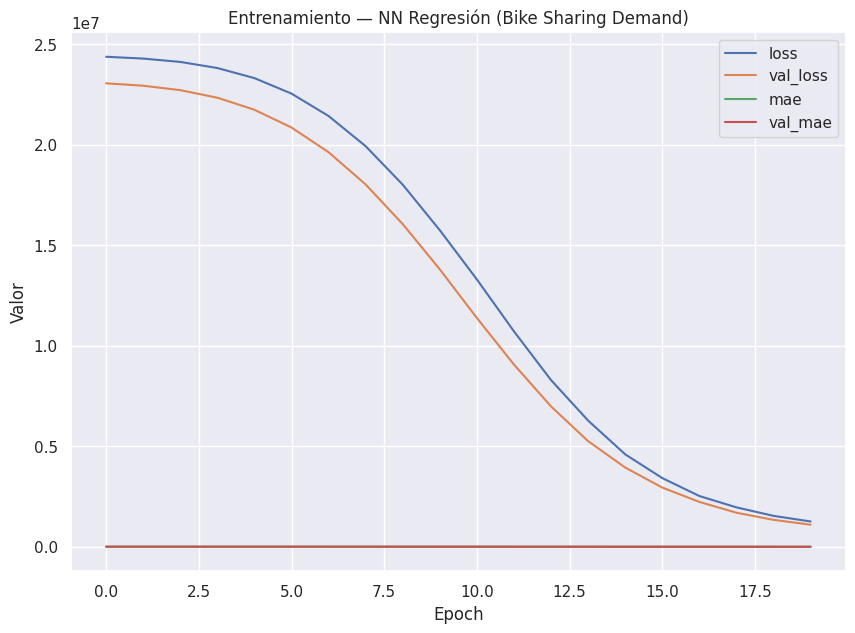

----------------------------------------
--- Evaluación del Modelo ---
Métricas de evaluación en el conjunto de prueba:
MAE:  803.859
RMSE: 1095502.625
R^2:  0.712
----------------------------------------


In [ ]:
# --- Bloque 2: Construcción y Compilación del Modelo ---
print("--- Construcción y Compilación del Modelo ---")
tf.keras.backend.clear_session()

# Definir la arquitectura de la red neuronal para regresión
reg_model = keras.Sequential([
    layers.Input(shape=(Xr_train_s.shape[1],)),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.1),
    layers.Dense(128, activation='relu'),
    layers.Dense(1, activation='linear') # Capa de salida lineal para regresión
])

# Compilar el modelo
reg_model.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss='mse', # Función de pérdida para regresión
    metrics=['mae', 'mse', tf.keras.metrics.RootMeanSquaredError(), tf.keras.metrics.R2Score()] # Métricas relevantes
)

reg_model.summary()
print("Modelo construido y compilado.")
print("-" * 40)


# --- Bloque 3: Entrenamiento del Modelo ---
print("--- Entrenamiento del Modelo ---")
# Definimos EarlyStopping con paciencia ajustada para este dataset
es = keras.callbacks.EarlyStopping(monitor='val_loss', patience=30, restore_best_weights=True)

# Entrenamos el modelo de regresión
hist_r = reg_model.fit(
    Xr_train_s, yr_train,
    validation_data=(Xr_valid_s, yr_valid),
    epochs=20, # Aumentamos las epochs ya que EarlyStopping lo detendrá
    batch_size=32, # Disminuimos el batch a 32
    verbose=1, # Poner en 1 para ver el progreso
    callbacks=[es]
)

print("Entrenamiento finalizado.")
print("-" * 40)

# Visualizamos las curvas de entrenamiento (MAE y Loss)
print("--- Curvas de Entrenamiento ---")
pd.DataFrame(hist_r.history)[["loss","val_loss","mae","val_mae"]].plot(figsize=(10,7))
plt.title("Entrenamiento — NN Regresión (Bike Sharing Demand)")
plt.xlabel("Epoch")
plt.ylabel("Valor")
plt.grid(True)
plt.show()
print("-" * 40)


# --- Bloque 4: Evaluación del Modelo ---
print("--- Evaluación del Modelo ---")
# Evaluación en el conjunto de prueba
pred_test = reg_model.predict(Xr_test_s, verbose=0).ravel()

# Calculamos las métricas de evaluación
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(yr_test, pred_test)
mse = mean_squared_error(yr_test, pred_test) # squared=False para MSE
r2 = r2_score(yr_test, pred_test)


print(f"Métricas de evaluación en el conjunto de prueba:")
print(f"MAE:  {mae:.3f}")
print(f"RMSE: {mse:.3f}")
print(f"R^2:  {r2:.3f}")
print("-" * 40)

--- Construcción y Compilación del Modelo ---


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │         7,680 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 40,705 (159.00 KB)

 Trainable params: 40,705 (159.00 KB)

 Non-trainable params: 0 (0.00 B)

Modelo construido y compilado.
----------------------------------------
--- Entrenamiento del Modelo ---
Epoch 1/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 3s 64ms/step - loss: 24813862.0000 - mae: 4594.1318 - mse: 24813862.0000 - r2_score: -5.7136 - root_mean_squared_error: 4980.6172 - val_loss: 22503150.0000 - val_mae: 4290.6592 - val_mse: 22503150.0000 - val_r2_score: -4.4134 - val_root_mean_squared_error: 4743.7485
Epoch 2/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 23809358.0000 - mae: 4500.7700 - mse: 23809358.0000 - r2_score: -5.5445 - root_mean_squared_error: 4878.5845 - val_loss: 19941136.0000 - val_mae: 4035.1455 - val_mse: 19941136.0000 - val_r2_score: -3.7971 - val_root_mean_squared_error: 4465.5498
Epoch 3/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 19280716.0000 - mae: 4053.3870 - mse: 19280716.0000 - r2_score: -4.7390 - root_mean_squared_error: 4390.2686 - val_loss: 13863873.0000 - val_mae: 3355.5618 - val_mse: 13863873.0000 - val_r2_score: -2.3351 - val_root_mean_squared_err

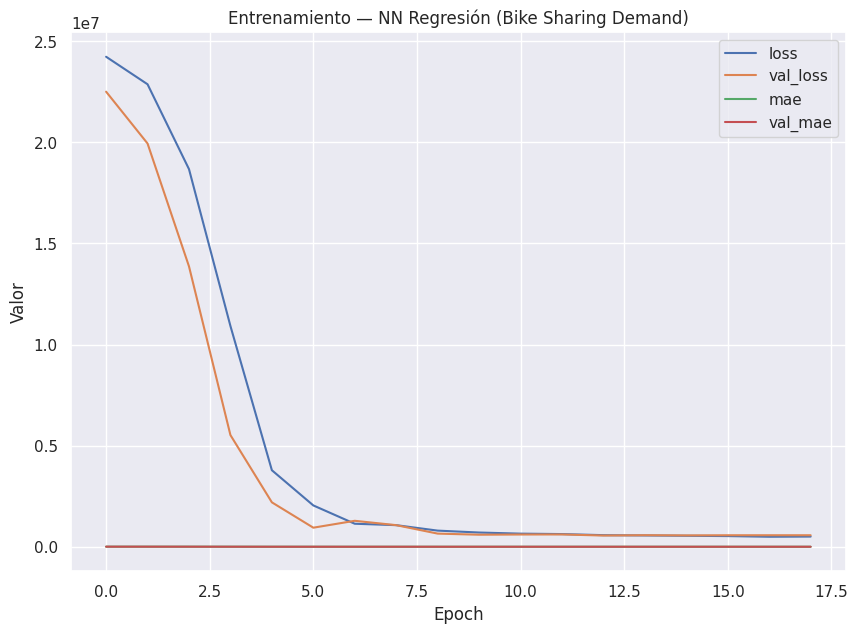

----------------------------------------
--- Evaluación del Modelo ---
Métricas de evaluación en el conjunto de prueba:
MAE:  626.755
RMSE: 627730.562
R^2:  0.835
----------------------------------------


In [ ]:
# --- Bloque 2: Construcción y Compilación del Modelo ---
print("--- Construcción y Compilación del Modelo ---")
tf.keras.backend.clear_session()

# Definir la arquitectura de la red neuronal para regresión
reg_model = keras.Sequential([
    layers.Input(shape=(Xr_train_s.shape[1],)),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.1),
    layers.Dense(128, activation='relu'),
    layers.Dense(1, activation='linear') # Capa de salida lineal para regresión
])

# Compilar el modelo
reg_model.compile(
    optimizer=keras.optimizers.Adam(1e-2),
    loss='mse', # Función de pérdida para regresión
    metrics=['mae', 'mse', tf.keras.metrics.RootMeanSquaredError(), tf.keras.metrics.R2Score()] # Métricas relevantes
)

reg_model.summary()
print("Modelo construido y compilado.")
print("-" * 40)


# --- Bloque 3: Entrenamiento del Modelo ---
print("--- Entrenamiento del Modelo ---")
# Definimos EarlyStopping con paciencia ajustada para este dataset
# Dismunuimos el patience a 5
es = keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

# Entrenamos el modelo de regresión
hist_r = reg_model.fit(
    Xr_train_s, yr_train,
    validation_data=(Xr_valid_s, yr_valid),
    epochs=20, # Aumentamos las epochs ya que EarlyStopping lo detendrá
    batch_size=64,
    verbose=1, # Poner en 1 para ver el progreso
    callbacks=[es]
)

print("Entrenamiento finalizado.")
print("-" * 40)

# Visualizamos las curvas de entrenamiento (MAE y Loss)
print("--- Curvas de Entrenamiento ---")
pd.DataFrame(hist_r.history)[["loss","val_loss","mae","val_mae"]].plot(figsize=(10,7))
plt.title("Entrenamiento — NN Regresión (Bike Sharing Demand)")
plt.xlabel("Epoch")
plt.ylabel("Valor")
plt.grid(True)
plt.show()
print("-" * 40)


# --- Bloque 4: Evaluación del Modelo ---
print("--- Evaluación del Modelo ---")
# Evaluación en el conjunto de prueba
pred_test = reg_model.predict(Xr_test_s, verbose=0).ravel()

# Calculamos las métricas de evaluación
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(yr_test, pred_test)
mse = mean_squared_error(yr_test, pred_test) # squared=False para MSE
r2 = r2_score(yr_test, pred_test)


print(f"Métricas de evaluación en el conjunto de prueba:")
print(f"MAE:  {mae:.3f}")
print(f"RMSE: {mse:.3f}")
print(f"R^2:  {r2:.3f}")
print("-" * 40)

--- Construcción y Compilación del Modelo ---


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │         6,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 48,129 (188.00 KB)

 Trainable params: 48,129 (188.00 KB)

 Non-trainable params: 0 (0.00 B)

Modelo construido y compilado.
----------------------------------------
--- Entrenamiento del Modelo ---
Epoch 1/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - loss: 24206146.0000 - mae: 4506.8008 - mse: 24206146.0000 - r2_score: -5.3173 - root_mean_squared_error: 4912.3013 - val_loss: 5822898.5000 - val_mae: 1991.4546 - val_mse: 5822898.5000 - val_r2_score: -0.4008 - val_root_mean_squared_error: 2413.0684
Epoch 2/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 2887338.7500 - mae: 1329.8748 - mse: 2887338.7500 - r2_score: 0.2011 - root_mean_squared_error: 1694.7577 - val_loss: 2134671.5000 - val_mae: 1168.4570 - val_mse: 2134671.5000 - val_r2_score: 0.4865 - val_root_mean_squared_error: 1461.0515
Epoch 3/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 1689585.8750 - mae: 1024.7030 - mse: 1689585.8750 - r2_score: 0.5353 - root_mean_squared_error: 1293.7856 - val_loss: 783105.0000 - val_mae: 604.6276 - val_mse: 783105.0000 - val_r2_score: 0.8116 - val_root_mean_squared_error: 884.9322


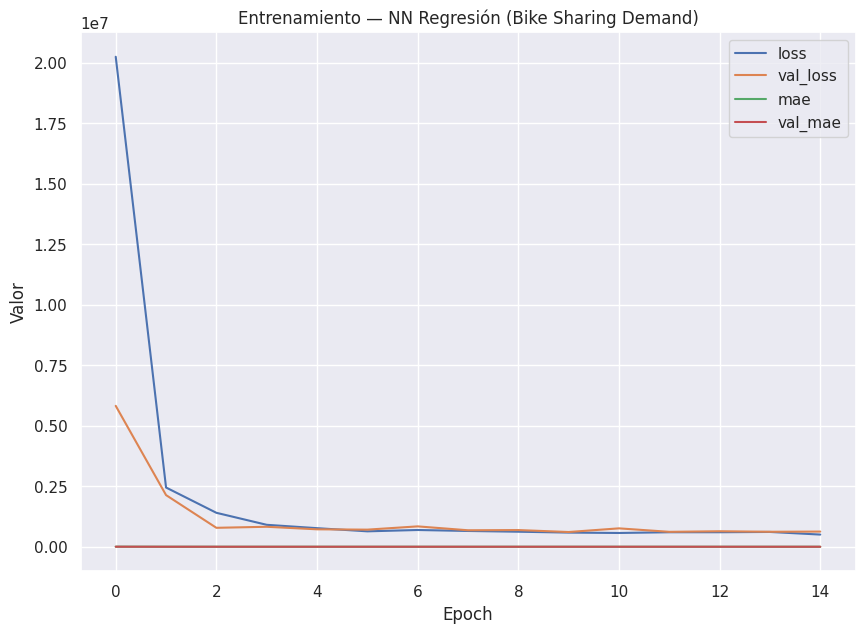

----------------------------------------
--- Evaluación del Modelo ---
Métricas de evaluación en el conjunto de prueba:
MAE:  571.037
RMSE: 561029.562
R^2:  0.852
----------------------------------------


In [ ]:
# --- Bloque 2: Construcción y Compilación del Modelo ---
print("--- Construcción y Compilación del Modelo ---")
tf.keras.backend.clear_session()

# Definir la arquitectura de la red neuronal para regresión
reg_model = keras.Sequential([
    layers.Input(shape=(Xr_train_s.shape[1],)),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='linear') # Capa de salida lineal para regresión
])

# Compilar el modelo
reg_model.compile(
    optimizer=keras.optimizers.Adam(1e-2),
    loss='mse', # Función de pérdida para regresión
    metrics=['mae', 'mse', tf.keras.metrics.RootMeanSquaredError(), tf.keras.metrics.R2Score()] # Métricas relevantes
)

reg_model.summary()
print("Modelo construido y compilado.")
print("-" * 40)


# --- Bloque 3: Entrenamiento del Modelo ---
print("--- Entrenamiento del Modelo ---")
# Definimos EarlyStopping con paciencia ajustada para este dataset
es = keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

# Entrenamos el modelo de regresión
hist_r = reg_model.fit(
    Xr_train_s, yr_train,
    validation_data=(Xr_valid_s, yr_valid),
    epochs=20, # Aumentamos las epochs ya que EarlyStopping lo detendrá
    batch_size=32,
    verbose=1, # Poner en 1 para ver el progreso
    callbacks=[es]
)

print("Entrenamiento finalizado.")
print("-" * 40)

# Visualizamos las curvas de entrenamiento (MAE y Loss)
print("--- Curvas de Entrenamiento ---")
pd.DataFrame(hist_r.history)[["loss","val_loss","mae","val_mae"]].plot(figsize=(10,7))
plt.title("Entrenamiento — NN Regresión (Bike Sharing Demand)")
plt.xlabel("Epoch")
plt.ylabel("Valor")
plt.grid(True)
plt.show()
print("-" * 40)


# --- Bloque 4: Evaluación del Modelo ---
print("--- Evaluación del Modelo ---")
# Evaluación en el conjunto de prueba
pred_test = reg_model.predict(Xr_test_s, verbose=0).ravel()

# Calculamos las métricas de evaluación
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(yr_test, pred_test)
mse = mean_squared_error(yr_test, pred_test) # squared=False para MSE
r2 = r2_score(yr_test, pred_test)


print(f"Métricas de evaluación en el conjunto de prueba:")
print(f"MAE:  {mae:.3f}")
print(f"RMSE: {mse:.3f}")
print(f"R^2:  {r2:.3f}")
print("-" * 40)

In [ ]:
# Para este ejercicio de regresión con datos diarios (day.csv), usaremos las siguientes características:
# Se quitan las características temp, hum, y windspeed
features_reg = ['season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday',
                'weathersit', 'atemp']
target_reg = 'cnt' # Total rental bikes

Xr = df_reg[features_reg]
yr = df_reg[target_reg]

# --- Bloque 1: Preparación y Partición de los datos ---
print("--- Preparación y Partición de los datos ---")
# Para las características categóricas en Xr, aplicaremos One-Hot Encoding
Xr = pd.get_dummies(Xr, columns=['season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit'], drop_first=True)


Xr_train, Xr_temp, yr_train, yr_temp = train_test_split(Xr, yr, test_size=0.3, random_state=42)
Xr_valid, Xr_test, yr_valid, yr_test = train_test_split(Xr_temp, yr_temp, test_size=0.5, random_state=42)

scaler_r = StandardScaler()
Xr_train_s = scaler_r.fit_transform(Xr_train)
Xr_valid_s = scaler_r.transform(Xr_valid)
Xr_test_s  = scaler_r.transform(Xr_test)

print("Dimensiones de los conjuntos de datos de regresión después de OHE y escalado:")
print(f"Entrenamiento: {Xr_train_s.shape}")
print(f"Validación:    {Xr_valid_s.shape}")
print(f"Prueba:        {Xr_test_s.shape}")
print("-" * 40)

--- Preparación y Partición de los datos ---
Dimensiones de los conjuntos de datos de regresión después de OHE y escalado:
Entrenamiento: (511, 26)
Validación:    (110, 26)
Prueba:        (110, 26)
----------------------------------------


--- Construcción y Compilación del Modelo ---


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │         6,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 48,129 (188.00 KB)

 Trainable params: 48,129 (188.00 KB)

 Non-trainable params: 0 (0.00 B)

Modelo construido y compilado.
----------------------------------------
--- Entrenamiento del Modelo ---
Epoch 1/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - loss: 23094418.0000 - mae: 4405.2358 - mse: 23094418.0000 - r2_score: -5.2549 - root_mean_squared_error: 4804.3320 - val_loss: 8433640.0000 - val_mae: 2464.5137 - val_mse: 8433640.0000 - val_r2_score: -1.0288 - val_root_mean_squared_error: 2904.0730
Epoch 2/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 5606243.0000 - mae: 1874.0858 - mse: 5606243.0000 - r2_score: -0.5115 - root_mean_squared_error: 2326.6292 - val_loss: 1668048.7500 - val_mae: 1056.1807 - val_mse: 1668048.7500 - val_r2_score: 0.5987 - val_root_mean_squared_error: 1291.5297
Epoch 3/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 1449708.3750 - mae: 980.7207 - mse: 1449708.3750 - r2_score: 0.6028 - root_mean_squared_error: 1202.0570 - val_loss: 804430.5000 - val_mae: 669.0209 - val_mse: 804430.5000 - val_r2_score: 0.8065 - val_root_mean_squared_error: 896.9005


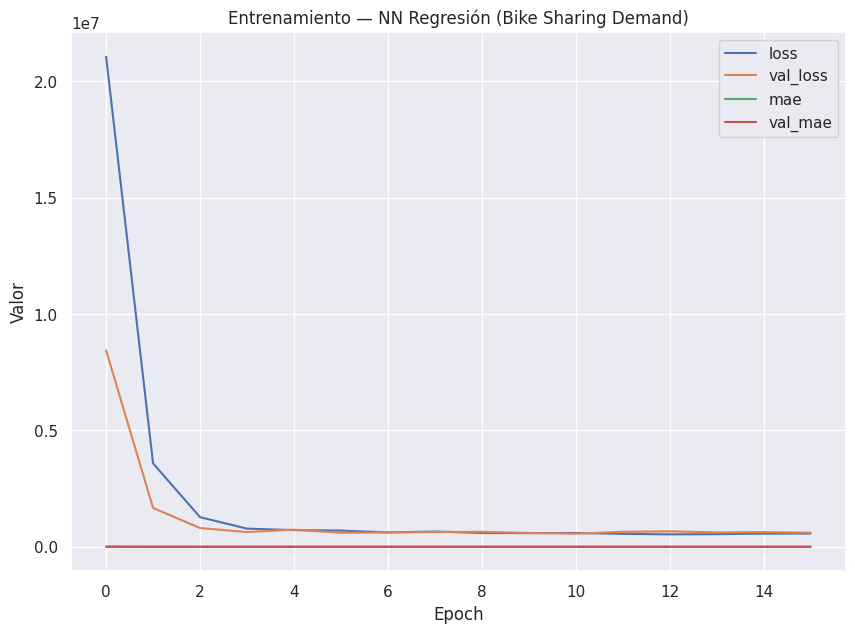

----------------------------------------
--- Evaluación del Modelo ---
Métricas de evaluación en el conjunto de prueba:
MAE:  593.472
RMSE: 569014.562
R^2:  0.850
----------------------------------------


In [ ]:
# --- Bloque 2: Construcción y Compilación del Modelo ---
print("--- Construcción y Compilación del Modelo ---")
tf.keras.backend.clear_session()

# Definir la arquitectura de la red neuronal para regresión
reg_model = keras.Sequential([
    layers.Input(shape=(Xr_train_s.shape[1],)),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='linear') # Capa de salida lineal para regresión
])

# Compilar el modelo
reg_model.compile(
    optimizer=keras.optimizers.Adam(1e-2),
    loss='mse', # Función de pérdida para regresión
    metrics=['mae', 'mse', tf.keras.metrics.RootMeanSquaredError(), tf.keras.metrics.R2Score()] # Métricas relevantes
)

reg_model.summary()
print("Modelo construido y compilado.")
print("-" * 40)


# --- Bloque 3: Entrenamiento del Modelo ---
print("--- Entrenamiento del Modelo ---")
# Definimos EarlyStopping con paciencia ajustada para este dataset
es = keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

# Entrenamos el modelo de regresión
hist_r = reg_model.fit(
    Xr_train_s, yr_train,
    validation_data=(Xr_valid_s, yr_valid),
    epochs=20, # Aumentamos las epochs ya que EarlyStopping lo detendrá
    batch_size=32,
    verbose=1, # Poner en 1 para ver el progreso
    callbacks=[es]
)

print("Entrenamiento finalizado.")
print("-" * 40)

# Visualizamos las curvas de entrenamiento (MAE y Loss)
print("--- Curvas de Entrenamiento ---")
pd.DataFrame(hist_r.history)[["loss","val_loss","mae","val_mae"]].plot(figsize=(10,7))
plt.title("Entrenamiento — NN Regresión (Bike Sharing Demand)")
plt.xlabel("Epoch")
plt.ylabel("Valor")
plt.grid(True)
plt.show()
print("-" * 40)


# --- Bloque 4: Evaluación del Modelo ---
print("--- Evaluación del Modelo ---")
# Evaluación en el conjunto de prueba
pred_test = reg_model.predict(Xr_test_s, verbose=0).ravel()

# Calculamos las métricas de evaluación
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(yr_test, pred_test)
mse = mean_squared_error(yr_test, pred_test) # squared=False para MSE
r2 = r2_score(yr_test, pred_test)


print(f"Métricas de evaluación en el conjunto de prueba:")
print(f"MAE:  {mae:.3f}")
print(f"RMSE: {mse:.3f}")
print(f"R^2:  {r2:.3f}")
print("-" * 40)

### **Experimentación y análisis**

**Modificación de Características de Entrenamiento**:

- Vuelve a la celda de preparación de datos (`741c505b`) y experimenta con las características utilizadas:
  1. Incluye o excluye algunas características originales (`season`, `yr`, `mnth`, `holiday`, `weekday`, `workingday`, `weathersit`, `temp`, `atemp`, `hum`, `windspeed`). Por ejemplo, podrías probar a quitar `atemp` o `windspeed`.
  2. Considera si alguna de las características categóricas (`season`, `yr`, `mnth`, etc.) debería ser tratada de forma diferente o si incluir/excluir alguna combinación de ellas impacta el resultado.
- Vuelve a entrenar y evaluar el modelo con el nuevo conjunto de características y compara los resultados (MAE, MSE, R²).


**Análisis de Resultados**:

- Compara el rendimiento (MAE, MSE, R²) de las diferentes configuraciones de la red neuronal y las diferentes selecciones de características en el conjunto de prueba. ¿Qué combinación funcionó mejor?
- Analiza las curvas de entrenamiento. ¿Hay signos de sobreajuste o subajuste en alguna configuración?
- ¿Qué características crees que son más importantes para predecir la demanda de bicicletas basándote en tus experimentos?
- ¿Cómo se compara el rendimiento de la red neuronal para regresión con lo que esperarías de un modelo tradicional en este problema?

## Respuesta

* De acuerdo a los resultados obtenidos, la tasa de aprendizaje alta (1e-2) fue el factor que más impacto tuvo en la curva de aprendizaje. Al combinarlo con un  batch size más pequeño (32), pudimos obtener los valores más bajos para el MAE y MSE, y un coeficiente de correlación máximo de 0.85. Sin embargo, este valor del R2 es aún bajo. Por ejemplo, el MAE indica que aproximadamente el modelo, para el mejor resultado, se equivoca en unas 580 a 600 unidades del valor real de la etiqueta. Esto sugiere que hay que seguir indagando y afinando los hiperparámetros para lograr mejores resultados.
* No. Al parecer no se presenta sobreajuste. Las curvas tienen un comportamiento similar y llegan a un mínimo en sus funciones de pérdida de forma muy cercana.
* Al eliminar las variables que se referían a condiciones ambientales, como temp, hum y windspeed, se pudieron obtener resultados similares a cuando se usaba el total de variables, por tanto, esto podría indicar que dichas condiciones no tienen un impacto muy significativo en la etiqueta.
* En este caso, la velocidad de cómputo parece ser más rápida, además de poder controlar las condiciones de parada para detener el modelo cuando los cálculos no cambien significativamente por medio del EarlyStopping. Sin embargo, parece que se necesita más cuidado y ser muy metodológico para afinar los hiperparámetros, lo cual puede conllevar a un trabajo exhaustivo para poder entrenar un modelo que se ajuste adecuadamente a los datos.